# Cart & Checkout — Behavioral Signals vs. Conversion
### Exploratory Data Analysis (EDA) — Google Colab Notebook

This notebook reproduces every chart and calculation used in the companion Word report,
**"Cart & Checkout Behavioral Signals — An Exploratory Analysis."**

**Scope of this notebook:** exploratory data analysis only. It does not propose a solution,
MVP, or product recommendation — it tests whether behavioral signals (payment failures,
promo attempts, price/stock changes, help opens, CSAT, checkout duration, cart value) help
explain differences in conversion across the 12 customer segments.

**How to run:** Runtime → Run all. When prompted, upload the challenge `.xlsx` dataset file.


## 0. Setup

In [7]:
# Install/confirm required libraries (Colab has these by default; kept for portability)
!pip install -q pandas matplotlib seaborn openpyxl python-docx numpy

import os

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk", font_scale=0.7)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"

FIGDIR = "figures"
os.makedirs(FIGDIR, exist_ok=True)

# Color palettes reused across every chart in this notebook, defined once.
CHANNEL_COLORS = {"App": "#2E74B5", "Desktop": "#C9A227", "Mobile Web": "#A13A2E"}
CART_TYPE_COLORS = {"Single delivery": "#2ca02c", "Multiple deliveries": "#d62728"}
USER_TYPE_COLORS = {"New": "#1f77b4", "Returning": "#ff7f0e"}


## 1. Load the Dataset

Upload the challenge `.xlsx` file when prompted (works in Google Colab). If you're running
this outside Colab, edit `SRC` below to point directly at the file path instead.

In [6]:
try:
    from google.colab import files
    print("Please upload the challenge .xlsx dataset file...")
    uploaded = files.upload()
    SRC = list(uploaded.keys())[0]
except ImportError:
    # Not running in Colab — set the path manually here instead
    SRC = "Hand_Up_1405___Cart___Checkout_Challenge_Dataset__4_.xlsx"

print("Using file:", SRC)


Please upload the challenge .xlsx dataset file...


Saving Hand Up 1405 _ Cart & Checkout Challenge Dataset (4).xlsx to Hand Up 1405 _ Cart & Checkout Challenge Dataset (4) (2).xlsx
Using file: Hand Up 1405 _ Cart & Checkout Challenge Dataset (4) (2).xlsx


## 2. Clean the Data

Each row represents one **segment** (channel × user type × cart type), not one user.

In [8]:
raw = pd.read_excel(SRC, sheet_name="Funnel Data")

# Drop the trailing formula-example rows / blank rows below the real segment table
df = raw.dropna(subset=["segment_id"]).copy()
df = df[df["segment_id"].astype(str).str.startswith("S")].reset_index(drop=True)

# Safety net: coerce all non-label columns to numeric
label_cols = ["segment_id", "channel", "user_type", "cart_type"]
num_cols = df.columns.drop(label_cols)
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")

df["segment_label"] = df["channel"] + " / " + df["user_type"] + " / " + df["cart_type"]

print(f"Loaded {len(df)} segments.")
df.head(12)


Loaded 12 segments.


,segment_id,channel,user_type,cart_type,cart_sessions,cart→checkout,checkout_started,checkout→address,address_completed,address→delivery,...,orders_completed,overall conversion,avg_cart_value_k_toman,payment_failed_sessions,promo_attempt_sessions,price_or_stock_change_sessions,help_open_sessions,checkout_csat_100,median_checkout_seconds,segment_label
0,S03,App,Returning,Single delivery,52000.0,76.0,39520.0,95.000000,37544.0,93.999041,...,30844.0,59.315385,1850.0,1676.0,12480.0,1560.0,3120.0,82.0,150.0,App / Returning / Single delivery
1,S04,App,Returning,Multiple deliveries,36000.0,72.0,25920.0,93.001543,24106.0,72.998424,...,14887.0,41.352778,2800.0,992.0,9720.0,2880.0,5400.0,67.0,245.0,App / Returning / Multiple deliveries
2,S01,App,New,Single delivery,32000.0,66.0,21120.0,78.001894,16474.0,91.999514,...,12271.0,38.346875,1650.0,1116.0,12160.0,1600.0,3840.0,70.0,250.0,App / New / Single delivery
3,S07,Mobile Web,Returning,Single delivery,24000.0,68.0,16320.0,89.001225,14525.0,92.000000,...,10579.0,44.079167,1600.0,1094.0,7200.0,960.0,2400.0,73.0,220.0,Mobile Web / Returning / Single delivery
4,S02,App,New,Multiple deliveries,22000.0,61.0,13420.0,74.001490,9931.0,70.003021,...,5440.0,24.727273,2350.0,569.0,9460.0,1980.0,3960.0,60.0,340.0,App / New / Multiple deliveries
5,S11,Desktop,Returning,Single delivery,14000.0,73.0,10220.0,93.003914,9505.0,94.003156,...,6684.0,47.742857,2600.0,944.0,3780.0,420.0,1120.0,74.0,205.0,Desktop / Returning / Single delivery
6,S08,Mobile Web,Returning,Multiple deliveries,15000.0,64.0,9600.0,86.000000,8256.0,69.004360,...,4358.0,29.053333,2500.0,513.0,5250.0,1500.0,2700.0,58.0,330.0,Mobile Web / Returning / Multiple deliveries
7,S05,Mobile Web,New,Single delivery,28000.0,55.0,15400.0,58.000000,8932.0,88.994626,...,5943.0,21.225000,1400.0,778.0,12880.0,1680.0,5600.0,54.0,380.0,Mobile Web / New / Single delivery
8,S12,Desktop,Returning,Multiple deliveries,9000.0,69.0,6210.0,90.998390,5651.0,70.996284,...,2829.0,31.433333,3900.0,518.0,2880.0,810.0,1440.0,57.0,300.0,Desktop / Returning / Multiple deliveries
9,S09,Desktop,New,Single delivery,12000.0,62.0,7440.0,72.002688,5357.0,91.002427,...,3437.0,28.641667,2200.0,629.0,4920.0,600.0,1680.0,61.0,310.0,Desktop / New / Single delivery


## 3. Derive Behavioral Signal Rates

Raw session counts aren't comparable across segments of very different size, so each signal
is converted into a rate using the most logically relevant denominator (e.g., payment
failures ÷ sessions that *reached* payment, not ÷ total cart sessions).

In [9]:
df["payment_failure_rate"]    = df["payment_failed_sessions"]        / df["payment_started"]  * 100
df["promo_attempt_rate"]      = df["promo_attempt_sessions"]         / df["cart_sessions"]     * 100
df["price_stock_change_rate"] = df["price_or_stock_change_sessions"] / df["cart_sessions"]     * 100
df["help_open_rate"]          = df["help_open_sessions"]             / df["cart_sessions"]     * 100

METRIC_COLS = [
    "overall conversion", "payment→order", "payment_failure_rate", "promo_attempt_rate",
    "price_stock_change_rate", "help_open_rate", "checkout_csat_100",
    "median_checkout_seconds", "avg_cart_value_k_toman",
]

df[["segment_id", "segment_label"] + METRIC_COLS].round(2)


,segment_id,segment_label,overall conversion,payment→order,payment_failure_rate,promo_attempt_rate,price_stock_change_rate,help_open_rate,checkout_csat_100,median_checkout_seconds,avg_cart_value_k_toman
0,S03,App / Returning / Single delivery,59.32,92.00,5.00,24.0,3.0,6.0,82.0,150.0,1850.0
1,S04,App / Returning / Multiple deliveries,41.35,90.00,6.00,27.0,8.0,15.0,67.0,245.0,2800.0
2,S01,App / New / Single delivery,38.35,88.00,8.00,38.0,5.0,12.0,70.0,250.0,1650.0
3,S07,Mobile Web / Returning / Single delivery,44.08,87.00,9.00,30.0,4.0,10.0,73.0,220.0,1600.0
4,S02,App / New / Multiple deliveries,24.73,85.99,8.99,43.0,9.0,18.0,60.0,340.0,2350.0
5,S11,Desktop / Returning / Single delivery,47.74,85.01,12.01,27.0,3.0,8.0,74.0,205.0,2600.0
6,S08,Mobile Web / Returning / Multiple deliveries,29.05,85.00,10.01,35.0,10.0,18.0,58.0,330.0,2500.0
7,S05,Mobile Web / New / Single delivery,21.22,84.00,11.00,46.0,6.0,20.0,54.0,380.0,1400.0
8,S12,Desktop / Returning / Multiple deliveries,31.43,82.00,15.01,32.0,9.0,16.0,57.0,300.0,3900.0
9,S09,Desktop / New / Single delivery,28.64,81.99,15.00,41.0,5.0,14.0,61.0,310.0,2200.0


In [10]:
# Data-quality check: confirm each funnel stage narrows monotonically per segment,
# and flag any missing values in the signal columns used below.
funnel_cols = ["cart_sessions", "checkout_started", "address_completed",
               "delivery_selected", "payment_started", "orders_completed"]
monotonic_ok = df[funnel_cols].apply(lambda r: all(r.iloc[i] >= r.iloc[i + 1] for i in range(len(r) - 1)), axis=1)
print("Funnel narrows monotonically for all segments:", bool(monotonic_ok.all()))

missing = df[METRIC_COLS].isna().sum()
print("\nMissing values per metric:")
print(missing[missing > 0] if missing.sum() else "None")


Funnel narrows monotonically for all segments: True

Missing values per metric:
checkout_csat_100    1
dtype: int64


## 4. Helper Functions for Charting

Bubble size encodes the relevant session volume for that chart, and every point is labeled
with its `segment_id` so it can be traced back to a specific row in the table above.

In [12]:
def seg_colors(frame):
    """Map each row's channel to its display color."""
    return frame["channel"].map(CHANNEL_COLORS)


def group_colors(frame, column, color_map):
    """Map any categorical column (cart_type / user_type / ...) to its display color."""
    return frame[column].map(color_map)


def legend_handles(color_map):
    """Build legend patches for a color map."""
    return [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]


def annotate_points(ax, x_series, y_series, labels_series):
    """Label each point with its segment_id, skipping any missing values."""
    for x, y, label in zip(x_series, y_series, labels_series):
        if pd.notna(x) and pd.notna(y):
            ax.annotate(str(label), (x, y), textcoords="offset points", xytext=(4, 4),
                        ha="center", fontsize=9)


channel_handles = legend_handles(CHANNEL_COLORS)
cart_type_handles = legend_handles(CART_TYPE_COLORS)
user_type_handles = legend_handles(USER_TYPE_COLORS)


def render_scatter(x, y, colors, sizes, labels, *, title, xlabel, ylabel,
                    legend_handles, legend_title, legend_loc, savepath,
                    vline=None, hline=None, note=None, figsize=(8, 6)):
    """Shared scatter-chart renderer: plot, annotate, style, save, and show.

    Used for every 'signal vs. conversion' chart in this notebook (base view plus the
    by-cart-type and by-user-type variants), so each chart cell only needs to compute
    its x/y/colors/sizes and call this function.
    """
    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(x, y, c=colors, s=sizes, edgecolor="white", linewidth=1, alpha=0.9)
    annotate_points(ax, x, y, labels)
    if vline is not None:
        ax.axvline(vline, color="gray", linestyle="--", linewidth=1)
    if hline is not None:
        ax.axhline(hline, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(handles=legend_handles, title=legend_title, loc=legend_loc)
    if note:
        ax.text(0.02, 0.02, note, transform=ax.transAxes, fontsize=8, color="gray")
    plt.tight_layout()
    plt.savefig(savepath)
    plt.show()


def render_heatmap(data, title, savepath, *, figsize=(9, 7), rotation=45,
                    linewidths=0.5, square=True, xlabel=None, ylabel=None):
    """Shared heatmap renderer for every correlation matrix in this notebook."""
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(data, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=square, linewidths=linewidths, cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title(title, pad=14)
    if xlabel:
        ax.set_xlabel(xlabel, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel)
    plt.xticks(rotation=rotation, ha="right")
    plt.tight_layout()
    plt.savefig(savepath)
    plt.show()


## 5. Chart 1 — Overall Conversion by Segment (Baseline)

**Why this chart:** a ranked horizontal bar chart makes it immediate which segments are
furthest from the average, without reading a table of percentages.
**How to read it:** bars are colored by channel; the dashed line marks the 12-segment average.

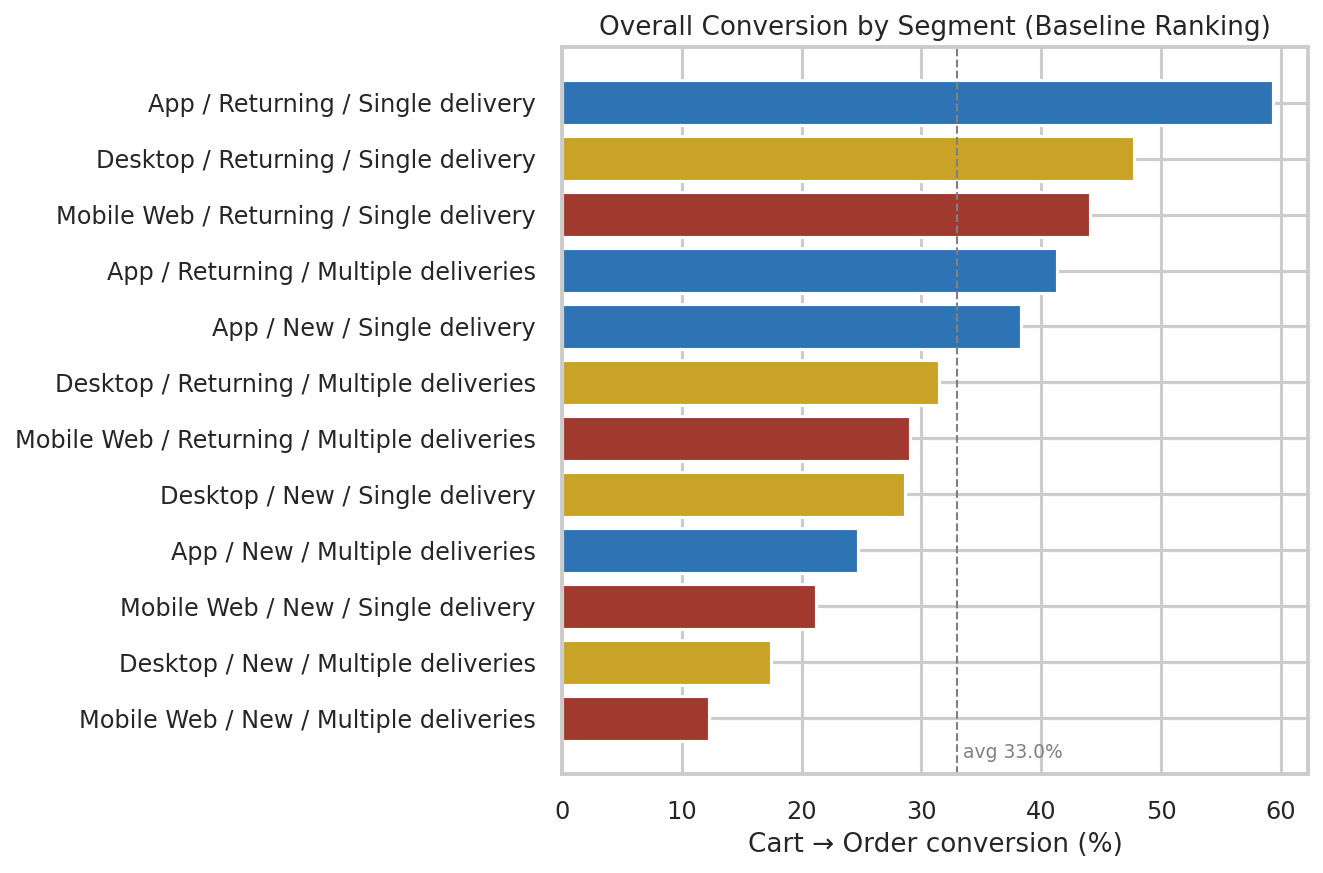

In [13]:
d = df.sort_values("overall conversion", ascending=True)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(d["segment_label"], d["overall conversion"], color=seg_colors(d))
ax.set_xlabel("Cart → Order conversion (%)")
ax.set_title("Overall Conversion by Segment (Baseline Ranking)")
avg = df["overall conversion"].mean()
ax.axvline(avg, color="gray", linestyle="--", linewidth=1)
ax.text(avg + 0.5, -0.7, f"avg {avg:.1f}%", color="gray", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/01_conversion_ranking.png")
plt.show()


## 6. Chart 2 — Payment Failures vs. Payment-Step Conversion

**Why this chart:** tests whether payment_failed_sessions (converted to a rate) explains
the Payment→Order step specifically, rather than the whole funnel at once.
**How to read it:** bottom-right = healthy (low failure, high conversion); top-left = risk.
**Correlation ≠ causation:** a strong relationship here shows the two move together across
segments — it does not by itself prove failures are causing lost orders.

Shown three ways: by channel (base view), by cart type, and by user type — the same
relationship, sliced along each of the three segment dimensions.

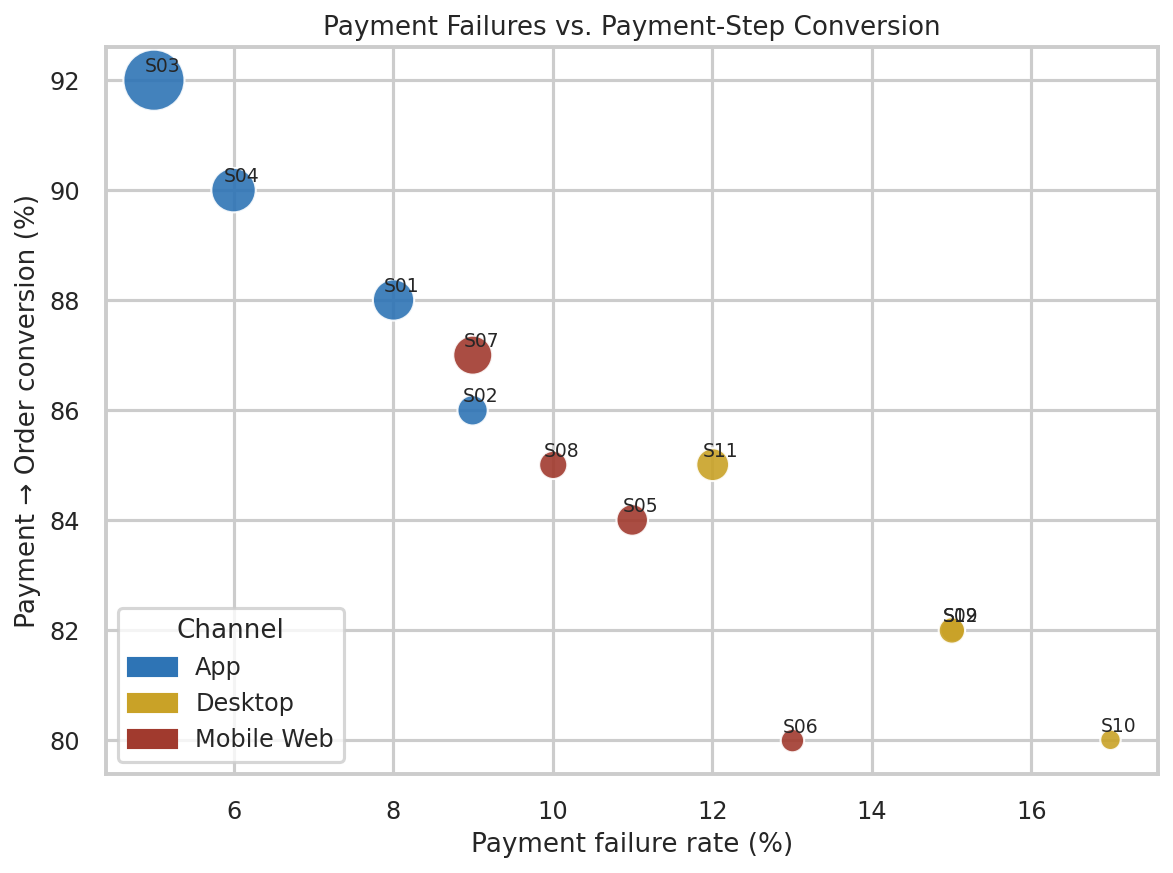

Correlation (payment_failure_rate vs payment→order): r = -0.95


In [14]:
sizes = df["payment_started"] / df["payment_started"].max() * 800 + 60

render_scatter(
    df["payment_failure_rate"], df["payment→order"], seg_colors(df), sizes, df["segment_id"],
    title="Payment Failures vs. Payment-Step Conversion",
    xlabel="Payment failure rate (%)", ylabel="Payment → Order conversion (%)",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="lower left",
    savepath=f"{FIGDIR}/02_payment_failure_vs_conversion.png",
)

r = df["payment_failure_rate"].corr(df["payment→order"])
print(f"Correlation (payment_failure_rate vs payment→order): r = {r:.2f}")


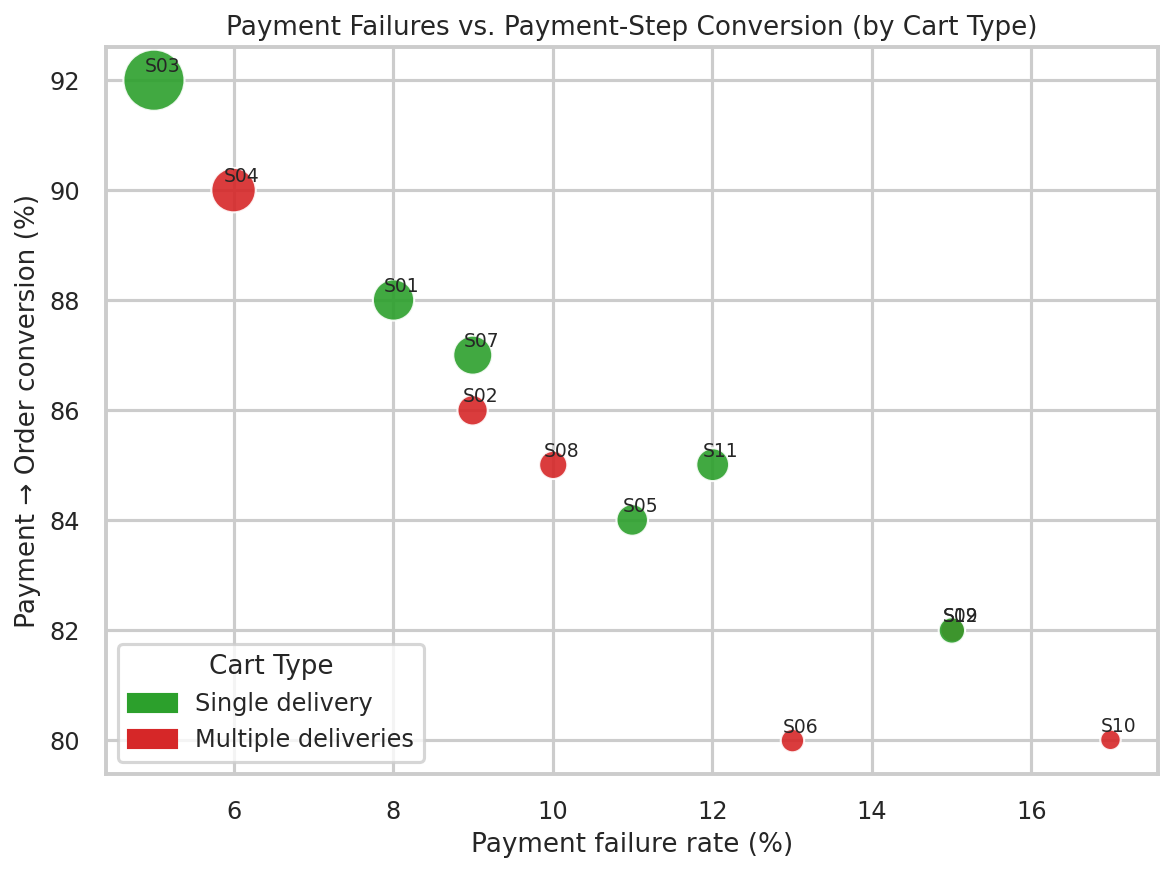

In [15]:
render_scatter(
    df["payment_failure_rate"], df["payment→order"], group_colors(df, "cart_type", CART_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Payment Failures vs. Payment-Step Conversion (by Cart Type)",
    xlabel="Payment failure rate (%)", ylabel="Payment → Order conversion (%)",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="lower left",
    savepath=f"{FIGDIR}/02_payment_failure_vs_conversion_cart_type.png",
)


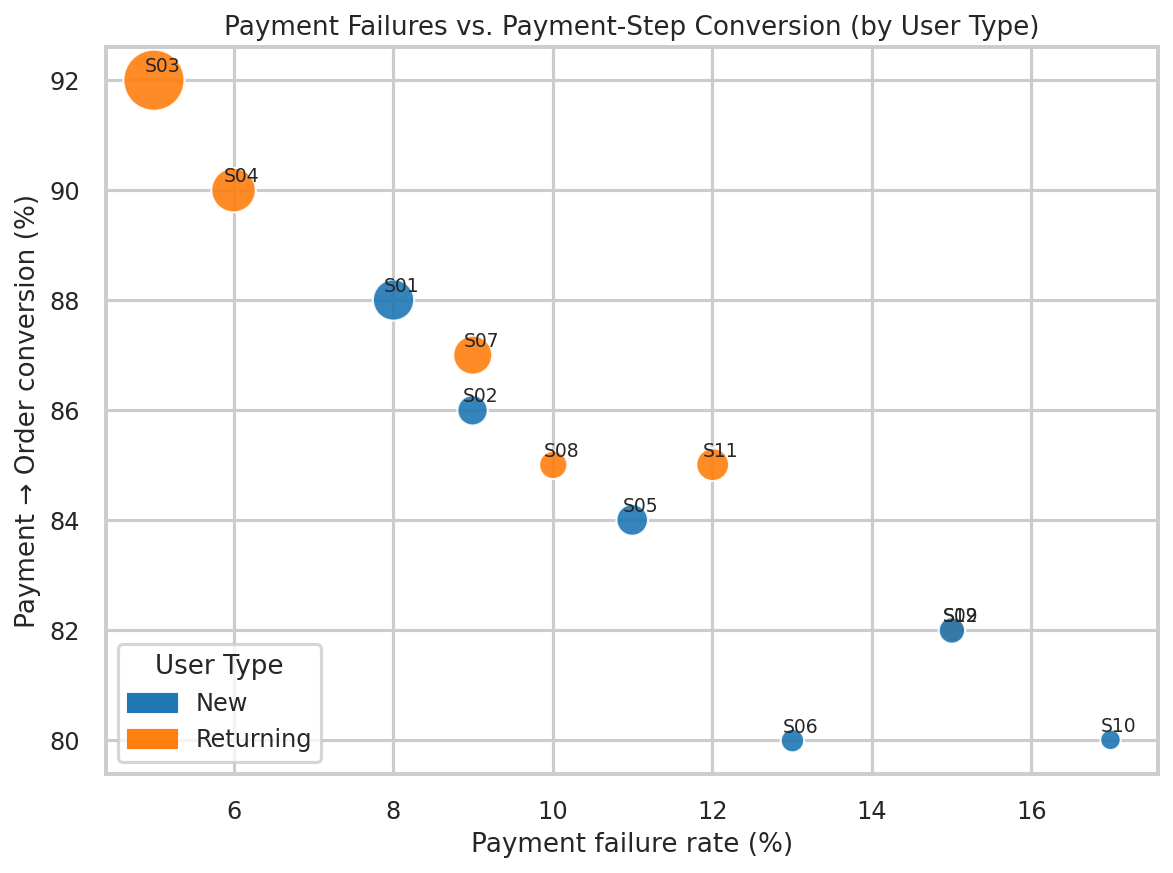

In [16]:
render_scatter(
    df["payment_failure_rate"], df["payment→order"], group_colors(df, "user_type", USER_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Payment Failures vs. Payment-Step Conversion (by User Type)",
    xlabel="Payment failure rate (%)", ylabel="Payment → Order conversion (%)",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="lower left",
    savepath=f"{FIGDIR}/02_payment_failure_vs_conversion_user_type.png",
)


## 7. Chart 3 — Promo-Code Attempts vs. Checkout Entry

**Why this chart:** Cart→Checkout is the single largest drop in the funnel on average, so it's
the highest-value stage to test signals against first.
**How to read it:** downward slope = segments that seek promos more also enter checkout less.

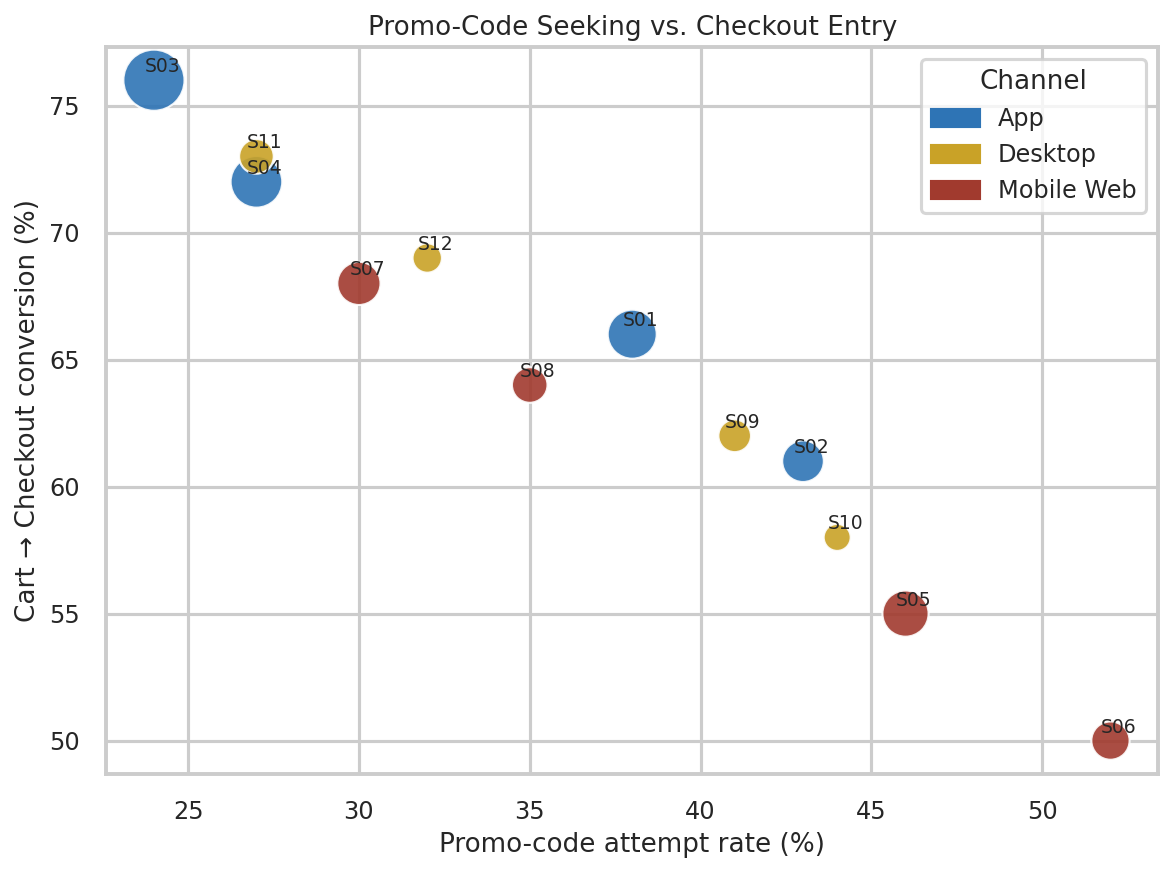

Correlation (promo_attempt_rate vs cart→checkout): r = -0.98


In [17]:
sizes = df["cart_sessions"] / df["cart_sessions"].max() * 800 + 60

render_scatter(
    df["promo_attempt_rate"], df["cart→checkout"], seg_colors(df), sizes, df["segment_id"],
    title="Promo-Code Seeking vs. Checkout Entry",
    xlabel="Promo-code attempt rate (%)", ylabel="Cart → Checkout conversion (%)",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="upper right",
    savepath=f"{FIGDIR}/03_promo_vs_cart_checkout.png",
)

r = df["promo_attempt_rate"].corr(df["cart→checkout"])
print(f"Correlation (promo_attempt_rate vs cart→checkout): r = {r:.2f}")


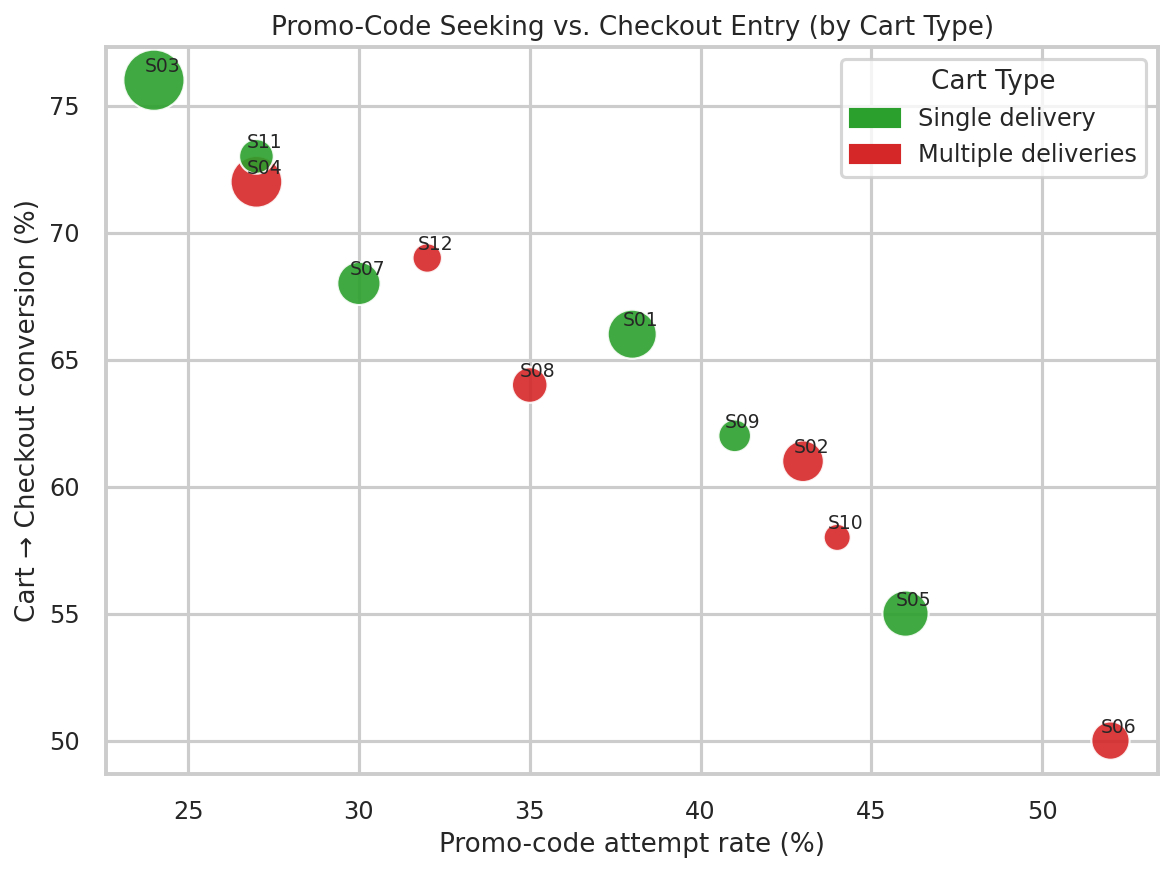

In [18]:
render_scatter(
    df["promo_attempt_rate"], df["cart→checkout"], group_colors(df, "cart_type", CART_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Promo-Code Seeking vs. Checkout Entry (by Cart Type)",
    xlabel="Promo-code attempt rate (%)", ylabel="Cart → Checkout conversion (%)",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="upper right",
    savepath=f"{FIGDIR}/03_promo_vs_cart_checkout_cart_type.png",
)


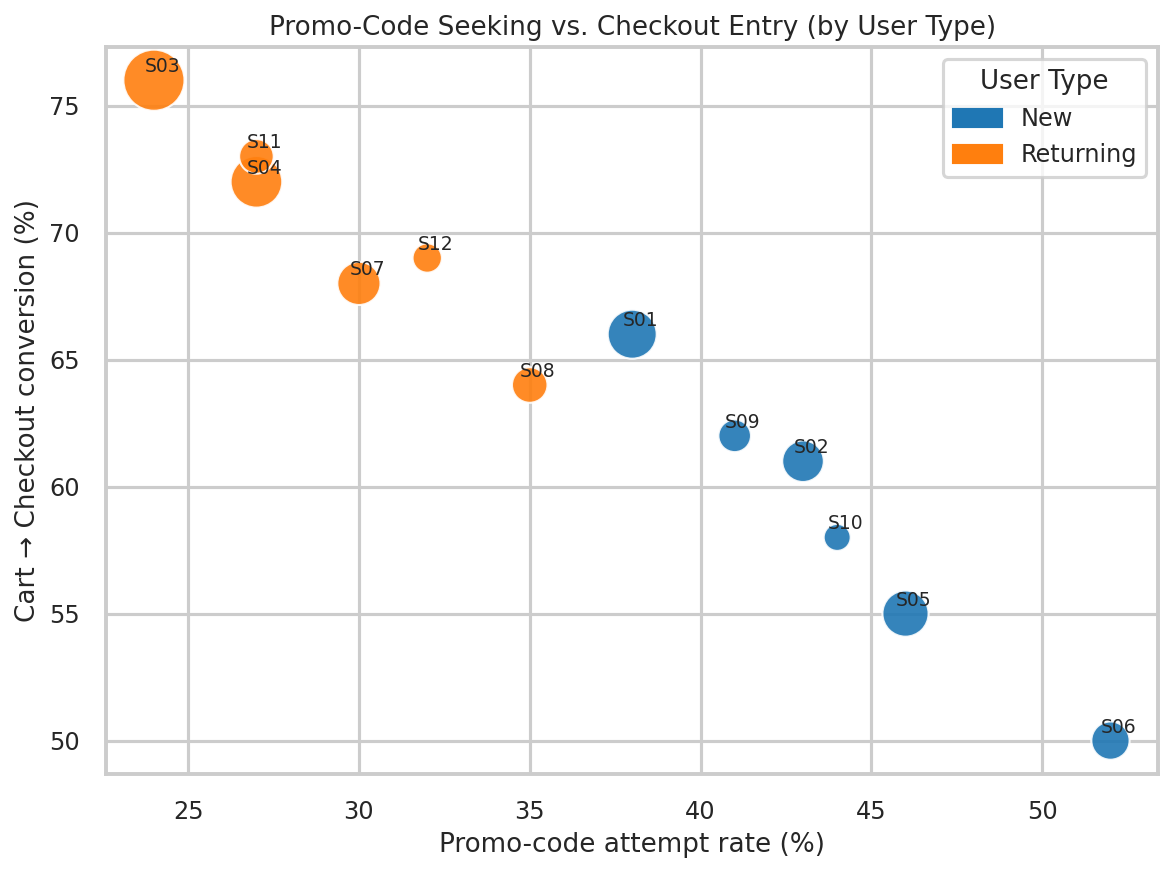

In [19]:
render_scatter(
    df["promo_attempt_rate"], df["cart→checkout"], group_colors(df, "user_type", USER_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Promo-Code Seeking vs. Checkout Entry (by User Type)",
    xlabel="Promo-code attempt rate (%)", ylabel="Cart → Checkout conversion (%)",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="upper right",
    savepath=f"{FIGDIR}/03_promo_vs_cart_checkout_user_type.png",
)


## 8. Chart 4 — Price/Stock Changes vs. Delivery-Step Conversion

**Why this chart:** a price or stock change most plausibly surfaces once a user is choosing
delivery options and seeing finalized costs, so it's tested against Address→Delivery.

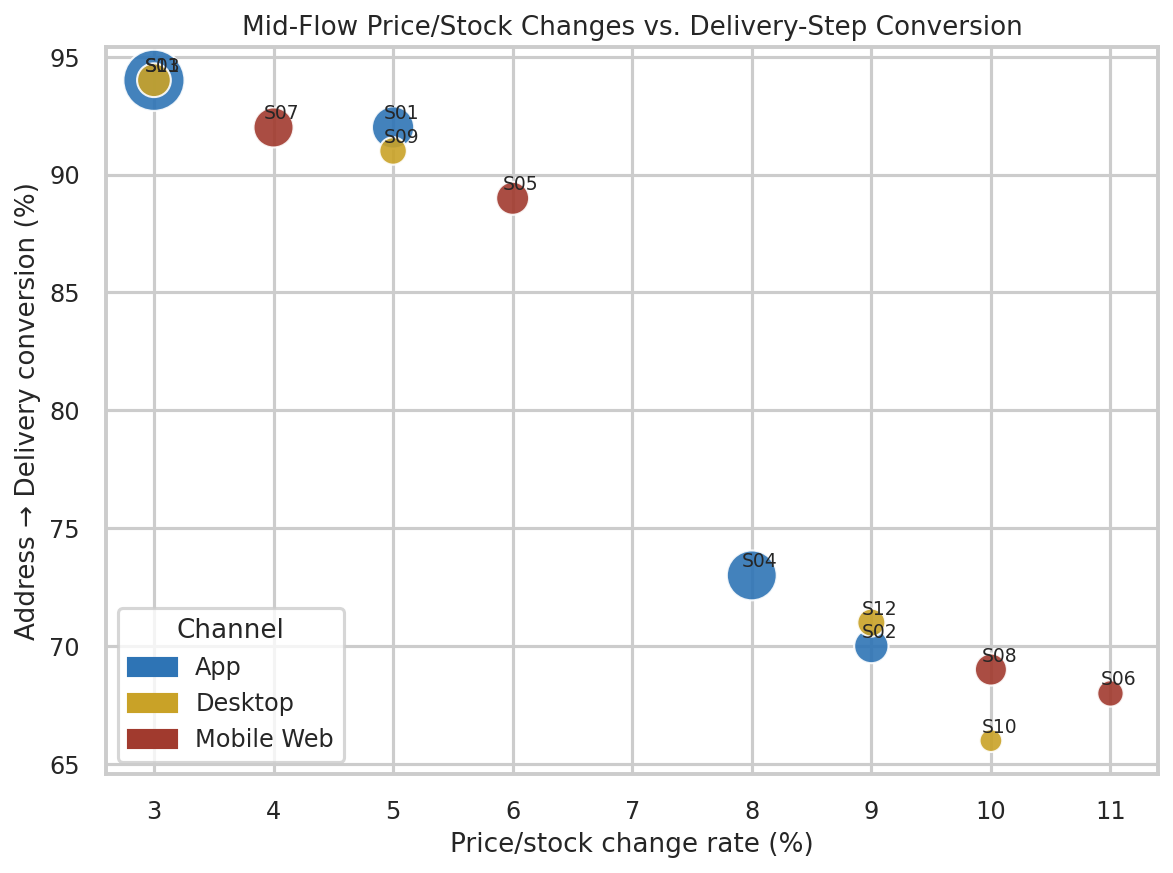

Correlation (price_stock_change_rate vs address→delivery): r = -0.97


In [20]:
sizes = df["address_completed"] / df["address_completed"].max() * 800 + 60

render_scatter(
    df["price_stock_change_rate"], df["address→delivery"], seg_colors(df), sizes, df["segment_id"],
    title="Mid-Flow Price/Stock Changes vs. Delivery-Step Conversion",
    xlabel="Price/stock change rate (%)", ylabel="Address → Delivery conversion (%)",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="lower left",
    savepath=f"{FIGDIR}/04_pricechange_vs_delivery.png",
)

r = df["price_stock_change_rate"].corr(df["address→delivery"])
print(f"Correlation (price_stock_change_rate vs address→delivery): r = {r:.2f}")


## 9. Chart 5 — Help-Seeking Behavior vs. Address-Step Conversion

**Why this chart:** help-desk opens are a direct signal of confusion; pairing with
Checkout→Address tests whether early-checkout confusion shows up in this signal.

The two cells below give the price/stock-change chart (Chart 4) its cart-type and user-type
variants, using the same `address_completed`-based sizing as the base chart above.

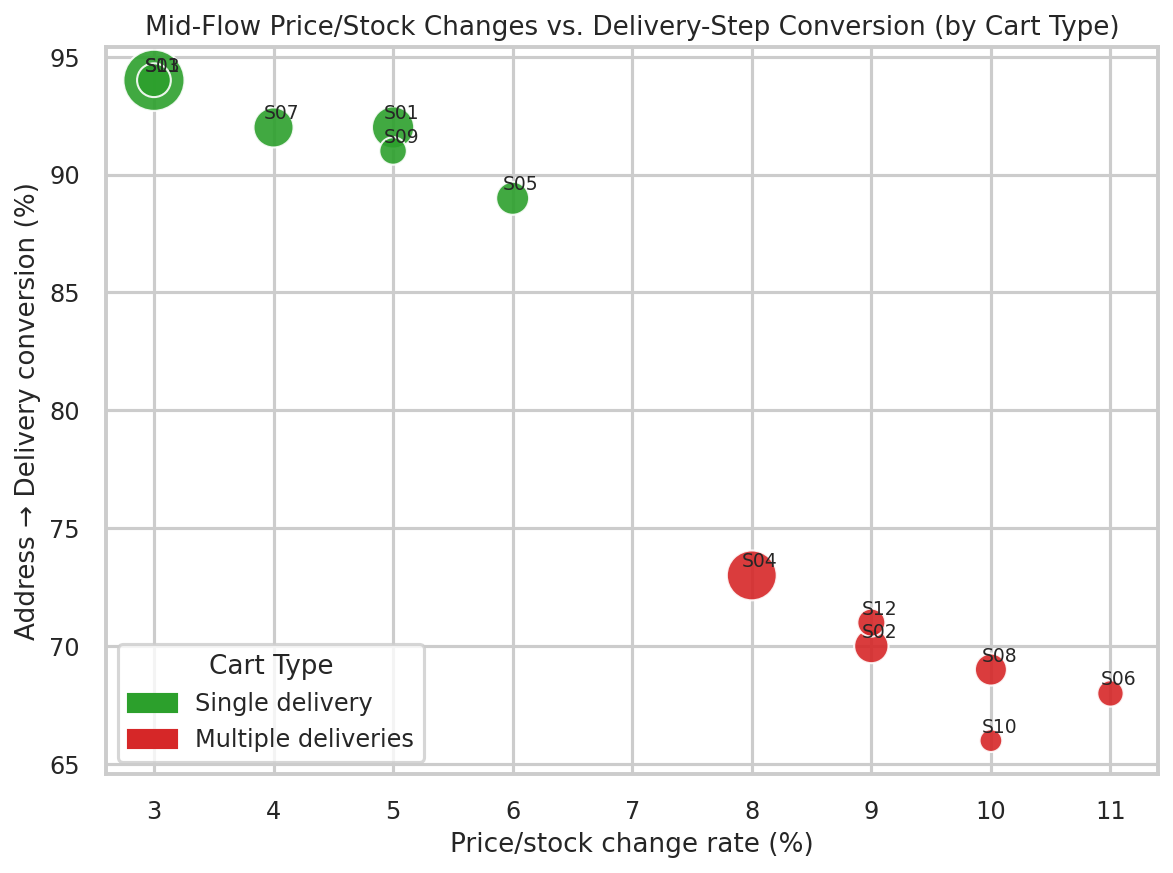

In [21]:
render_scatter(
    df["price_stock_change_rate"], df["address→delivery"], group_colors(df, "cart_type", CART_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Mid-Flow Price/Stock Changes vs. Delivery-Step Conversion (by Cart Type)",
    xlabel="Price/stock change rate (%)", ylabel="Address → Delivery conversion (%)",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="lower left",
    savepath=f"{FIGDIR}/04_pricechange_vs_delivery_cart_type.png",
)


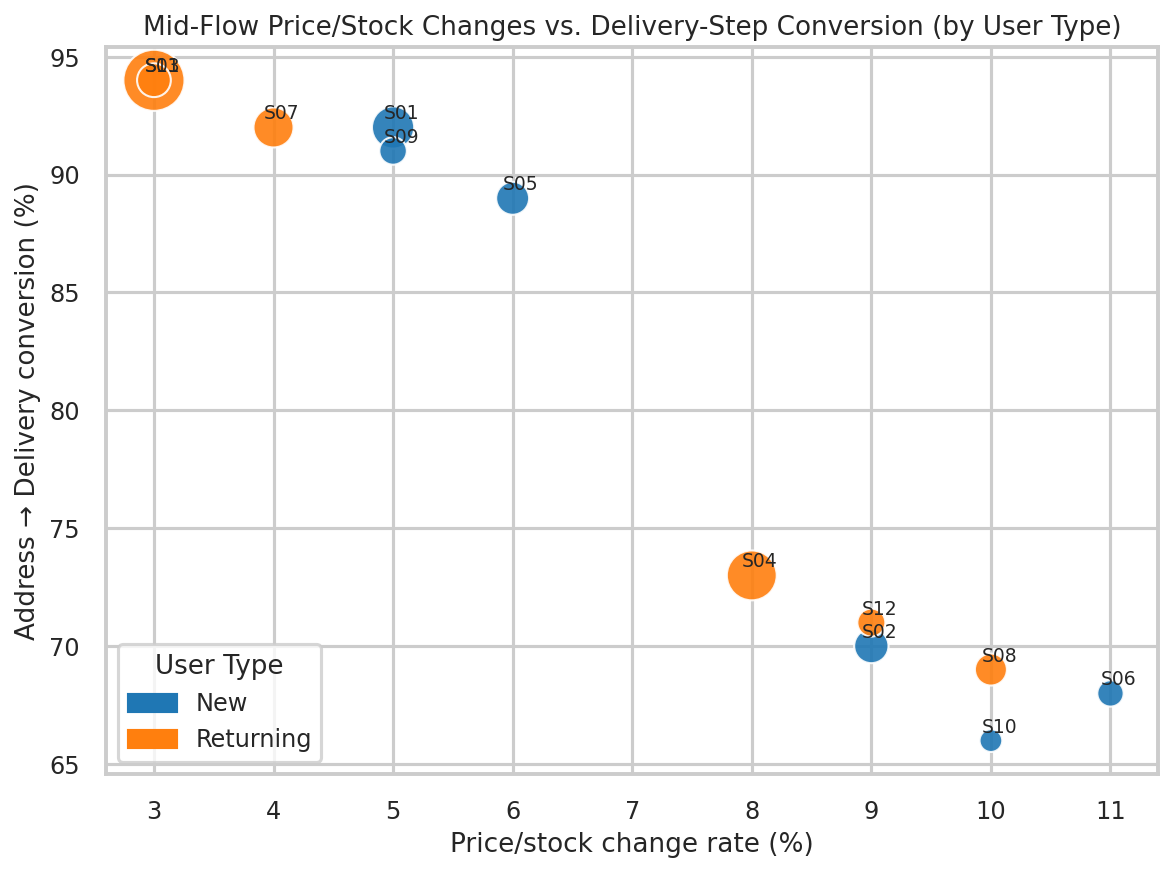

In [22]:
render_scatter(
    df["price_stock_change_rate"], df["address→delivery"], group_colors(df, "user_type", USER_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Mid-Flow Price/Stock Changes vs. Delivery-Step Conversion (by User Type)",
    xlabel="Price/stock change rate (%)", ylabel="Address → Delivery conversion (%)",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="lower left",
    savepath=f"{FIGDIR}/04_pricechange_vs_delivery_user_type.png",
)


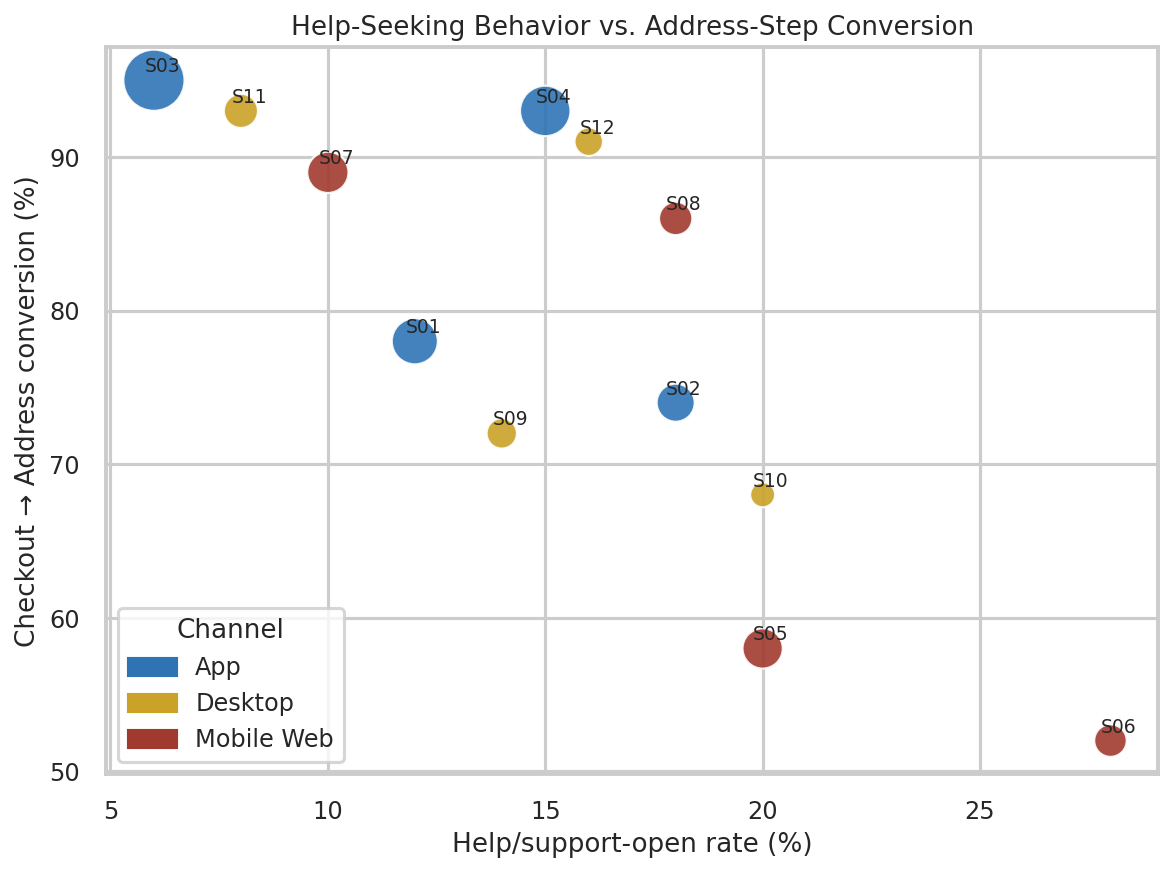

Correlation (help_open_rate vs checkout→address): r = -0.81


In [23]:
sizes = df["checkout_started"] / df["checkout_started"].max() * 800 + 60

render_scatter(
    df["help_open_rate"], df["checkout→address"], seg_colors(df), sizes, df["segment_id"],
    title="Help-Seeking Behavior vs. Address-Step Conversion",
    xlabel="Help/support-open rate (%)", ylabel="Checkout → Address conversion (%)",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="lower left",
    savepath=f"{FIGDIR}/05_help_vs_address.png",
)

r = df["help_open_rate"].corr(df["checkout→address"])
print(f"Correlation (help_open_rate vs checkout→address): r = {r:.2f}")


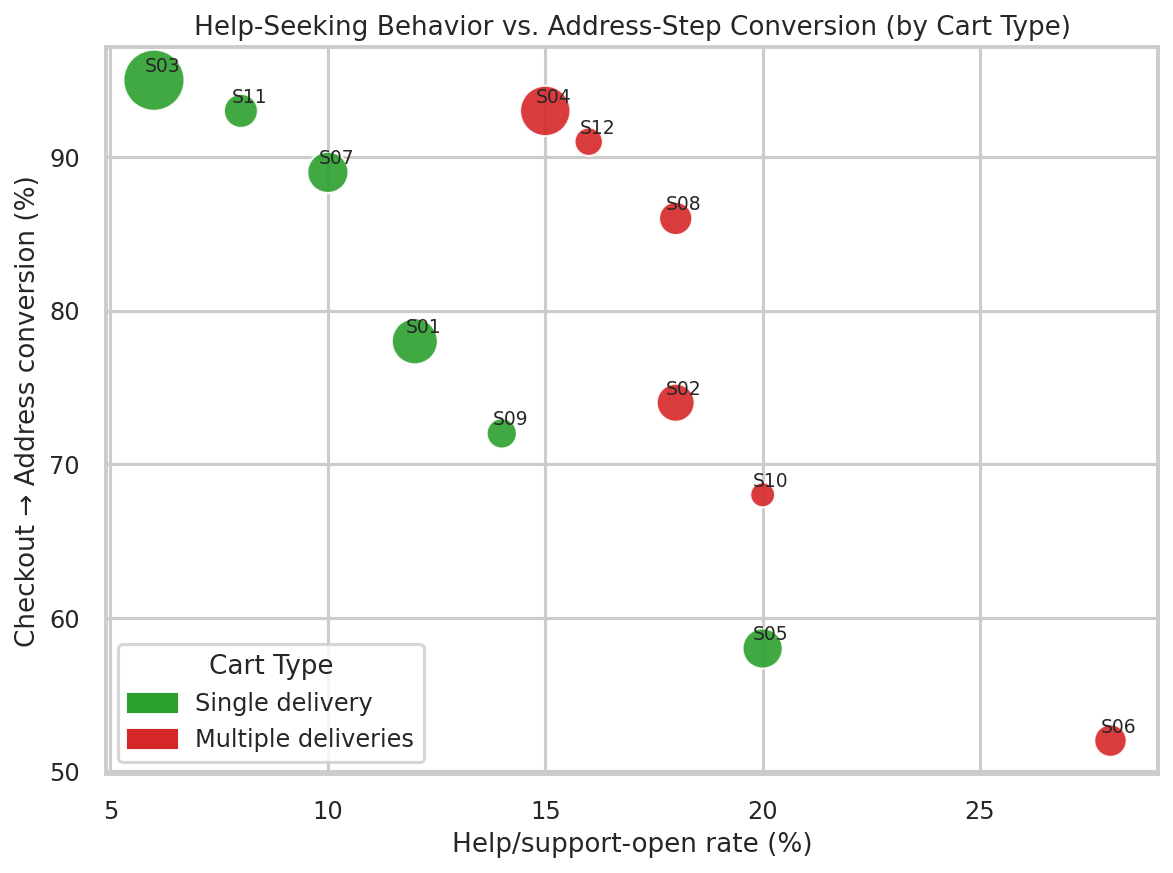

In [24]:
render_scatter(
    df["help_open_rate"], df["checkout→address"], group_colors(df, "cart_type", CART_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Help-Seeking Behavior vs. Address-Step Conversion (by Cart Type)",
    xlabel="Help/support-open rate (%)", ylabel="Checkout → Address conversion (%)",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="lower left",
    savepath=f"{FIGDIR}/05_help_vs_address_cart_type.png",
)


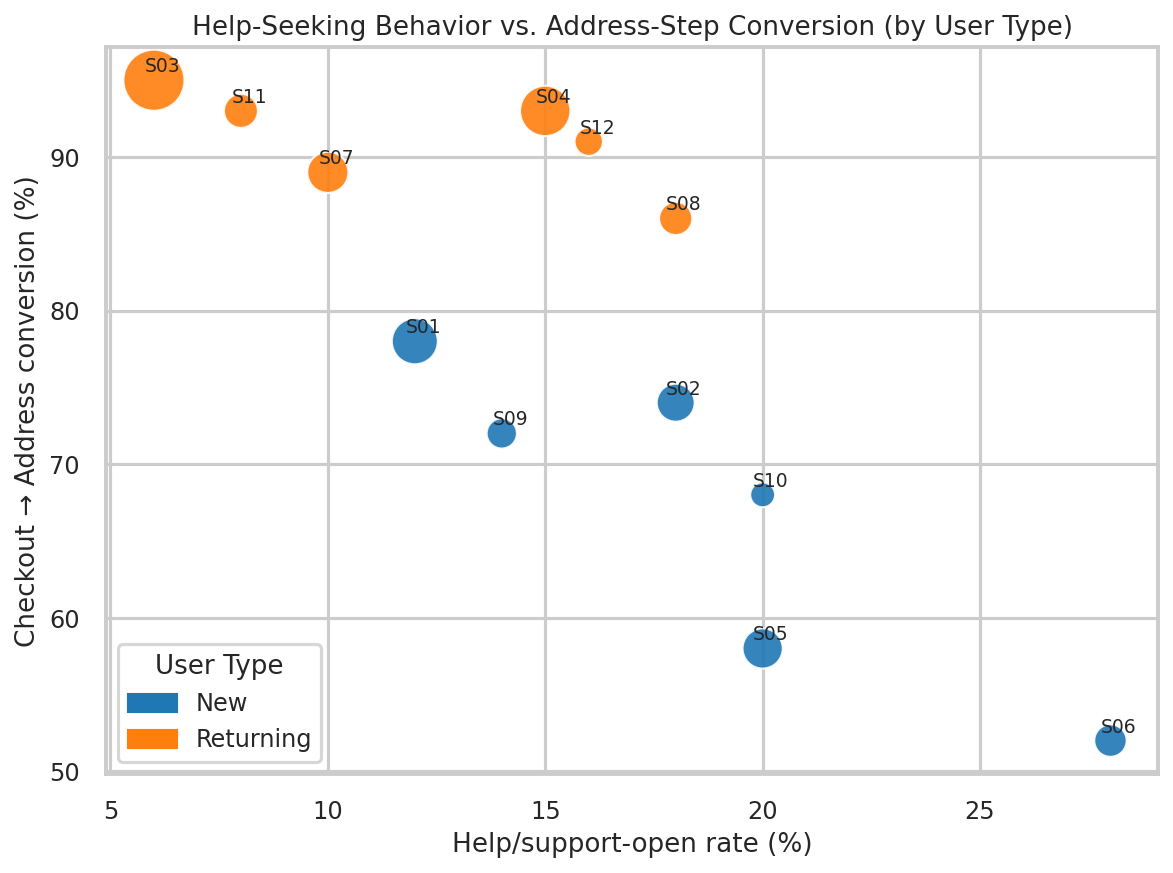

In [25]:
render_scatter(
    df["help_open_rate"], df["checkout→address"], group_colors(df, "user_type", USER_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Help-Seeking Behavior vs. Address-Step Conversion (by User Type)",
    xlabel="Help/support-open rate (%)", ylabel="Checkout → Address conversion (%)",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="lower left",
    savepath=f"{FIGDIR}/05_help_vs_address_user_type.png",
)


## 10. Chart 6 — Checkout Satisfaction (CSAT) vs. Overall Conversion

**Why this chart:** CSAT is self-reported, not behavioral — this tests whether subjective
satisfaction and actual completion tell the same story or diverge.
**Note:** one segment (S10) is missing a CSAT value in the source data and is excluded here.

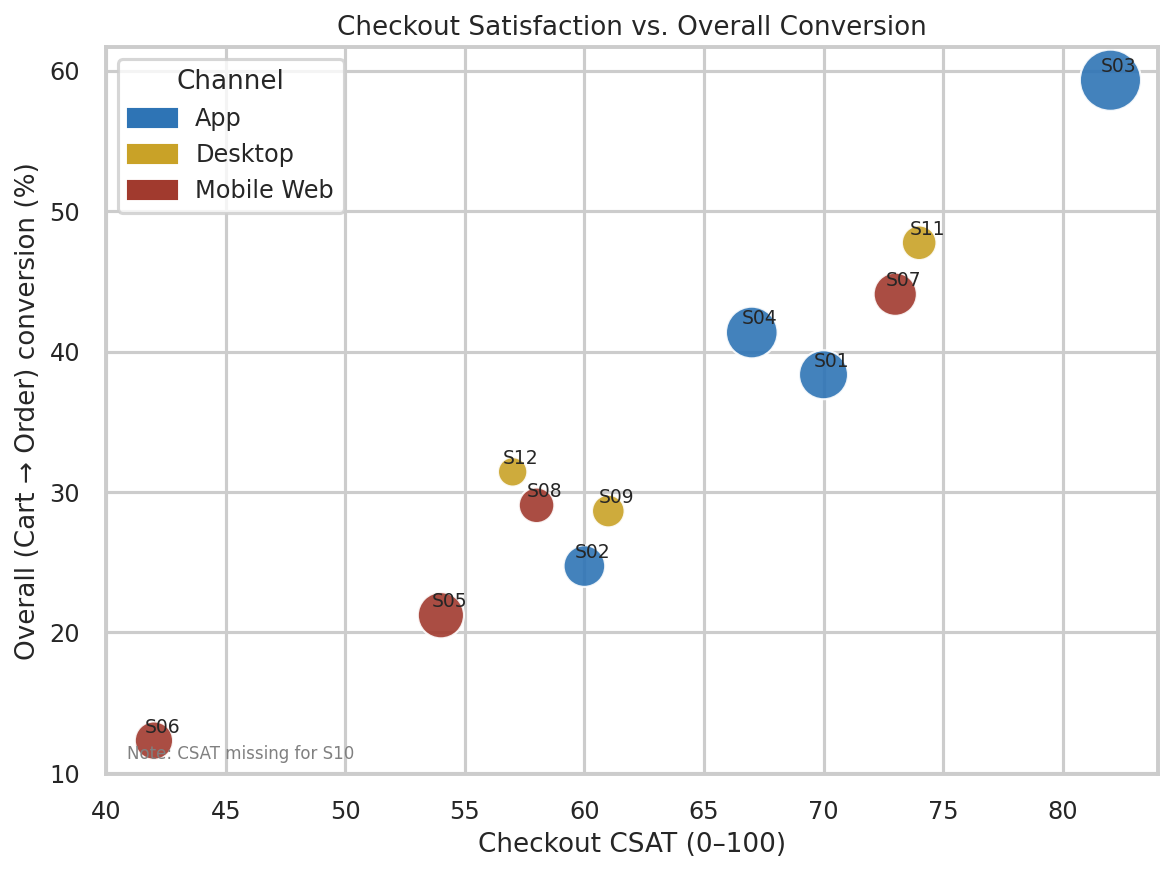

Correlation (checkout_csat_100 vs overall conversion): r = 0.97
Segments missing CSAT: ['S10']


In [26]:
d6 = df.dropna(subset=["checkout_csat_100"])
sizes = d6["cart_sessions"] / d6["cart_sessions"].max() * 800 + 60
missing = df[df["checkout_csat_100"].isna()]["segment_id"].tolist()
note = f"Note: CSAT missing for {', '.join(missing)}" if missing else None

render_scatter(
    d6["checkout_csat_100"], d6["overall conversion"], seg_colors(d6), sizes, d6["segment_id"],
    title="Checkout Satisfaction vs. Overall Conversion",
    xlabel="Checkout CSAT (0–100)", ylabel="Overall (Cart → Order) conversion (%)",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="upper left",
    savepath=f"{FIGDIR}/06_csat_vs_conversion.png", note=note,
)

r = d6["checkout_csat_100"].corr(d6["overall conversion"])
print(f"Correlation (checkout_csat_100 vs overall conversion): r = {r:.2f}")
print(f"Segments missing CSAT: {missing}")


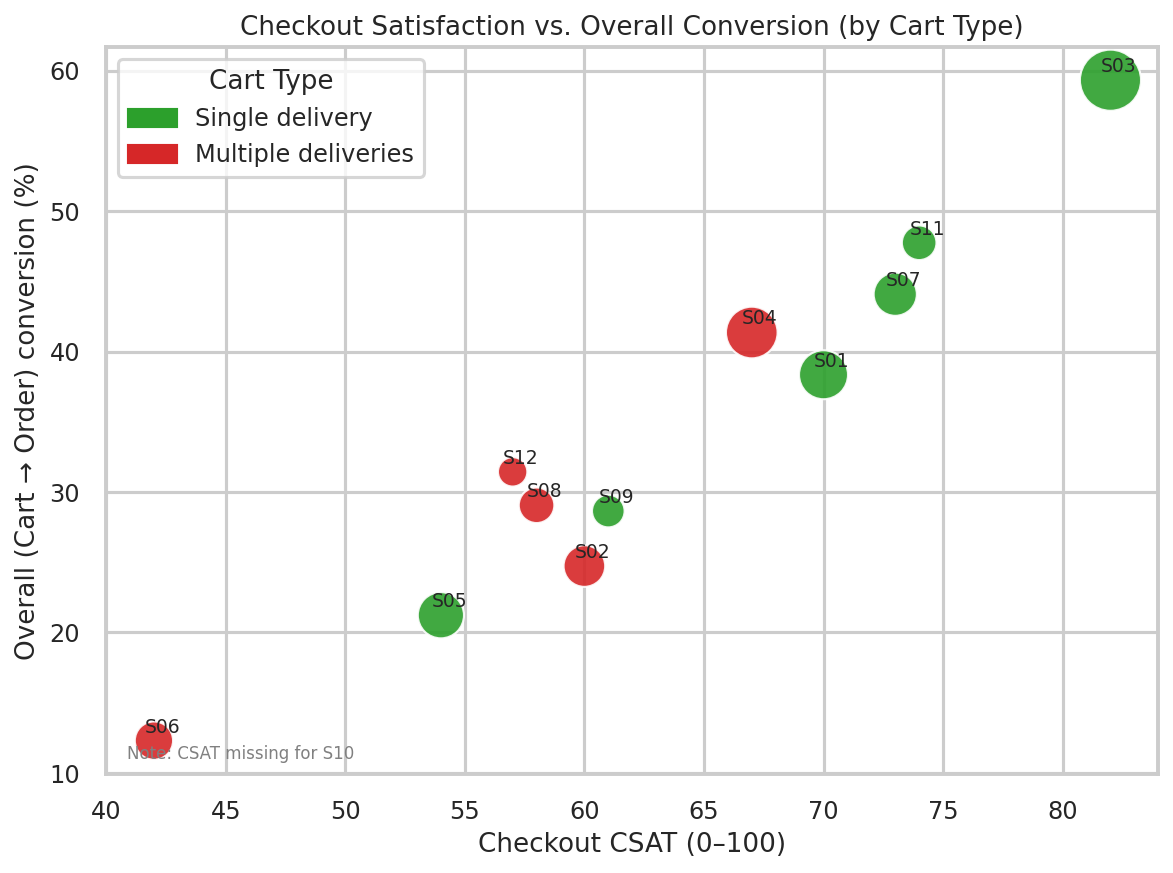

In [27]:
render_scatter(
    d6["checkout_csat_100"], d6["overall conversion"], group_colors(d6, "cart_type", CART_TYPE_COLORS),
    sizes, d6["segment_id"],
    title="Checkout Satisfaction vs. Overall Conversion (by Cart Type)",
    xlabel="Checkout CSAT (0–100)", ylabel="Overall (Cart → Order) conversion (%)",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="upper left",
    savepath=f"{FIGDIR}/06_csat_vs_conversion_cart_type.png", note=note,
)


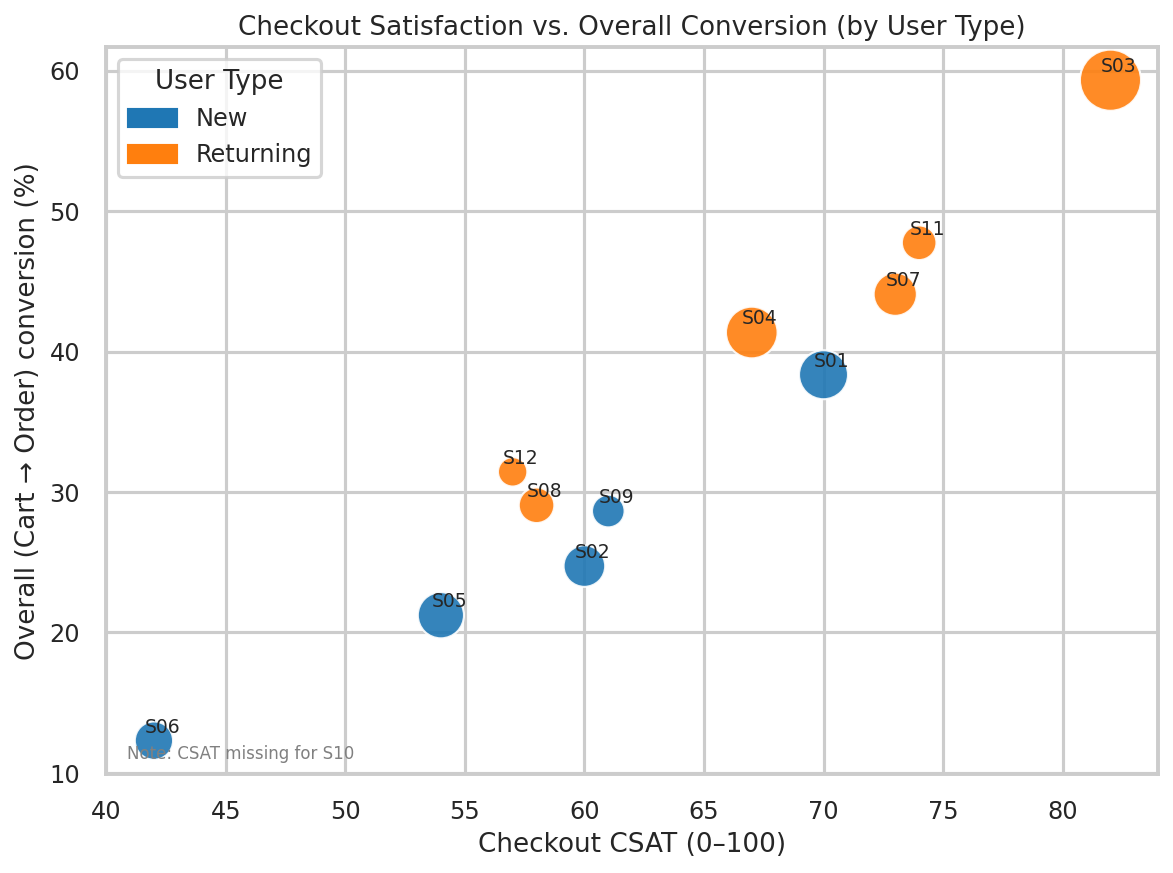

In [28]:
render_scatter(
    d6["checkout_csat_100"], d6["overall conversion"], group_colors(d6, "user_type", USER_TYPE_COLORS),
    sizes, d6["segment_id"],
    title="Checkout Satisfaction vs. Overall Conversion (by User Type)",
    xlabel="Checkout CSAT (0–100)", ylabel="Overall (Cart → Order) conversion (%)",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="upper left",
    savepath=f"{FIGDIR}/06_csat_vs_conversion_user_type.png", note=note,
)


## 11. Chart 7 — Checkout Duration vs. Overall Conversion

**Why this chart:** duration is an efficiency proxy — this checks whether longer checkouts
reflect friction (lower conversion) or deliberate, successful consideration (no relationship
or a positive one).

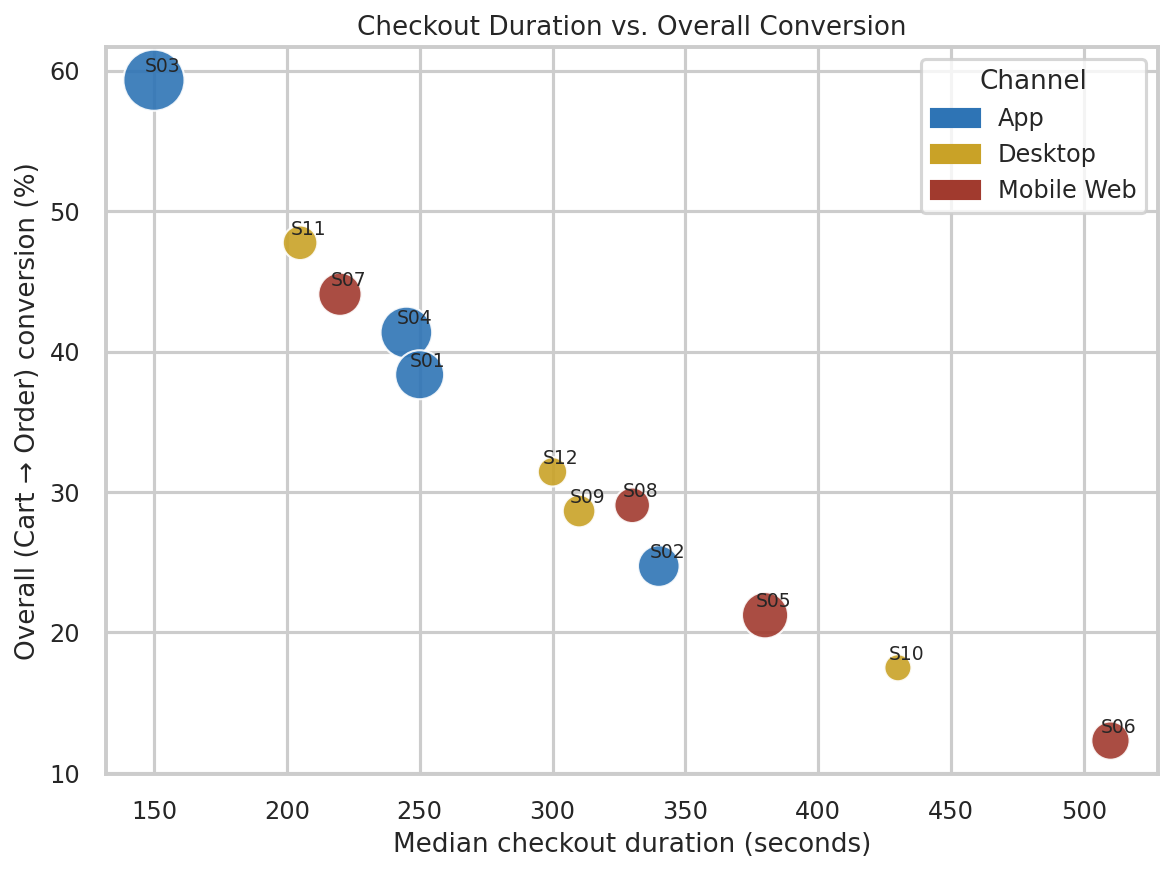

Correlation (median_checkout_seconds vs overall conversion): r = -0.97


In [29]:
sizes = df["cart_sessions"] / df["cart_sessions"].max() * 800 + 60

render_scatter(
    df["median_checkout_seconds"], df["overall conversion"], seg_colors(df), sizes, df["segment_id"],
    title="Checkout Duration vs. Overall Conversion",
    xlabel="Median checkout duration (seconds)", ylabel="Overall (Cart → Order) conversion (%)",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="upper right",
    savepath=f"{FIGDIR}/07_duration_vs_conversion.png",
)

r = df["median_checkout_seconds"].corr(df["overall conversion"])
print(f"Correlation (median_checkout_seconds vs overall conversion): r = {r:.2f}")


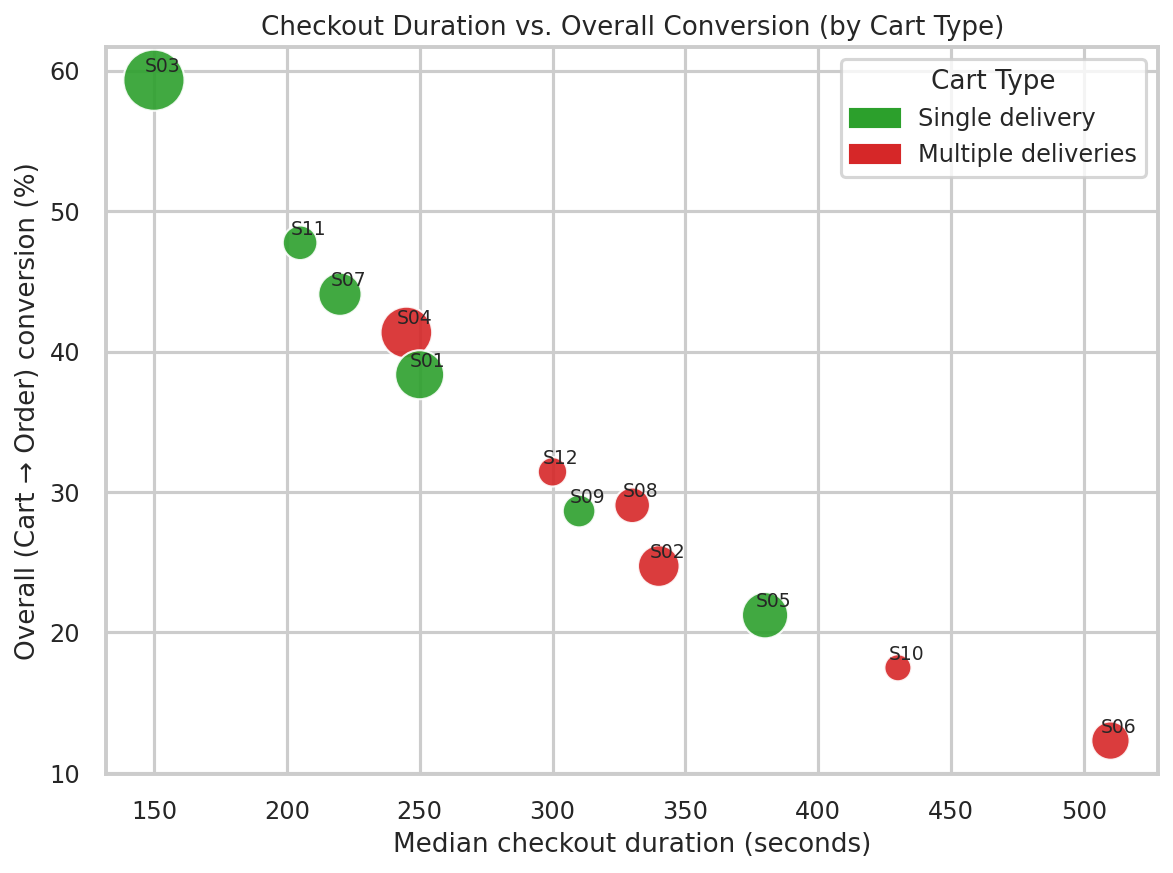

In [30]:
render_scatter(
    df["median_checkout_seconds"], df["overall conversion"], group_colors(df, "cart_type", CART_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Checkout Duration vs. Overall Conversion (by Cart Type)",
    xlabel="Median checkout duration (seconds)", ylabel="Overall (Cart → Order) conversion (%)",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="upper right",
    savepath=f"{FIGDIR}/07_duration_vs_conversion_cart_type.png",
)


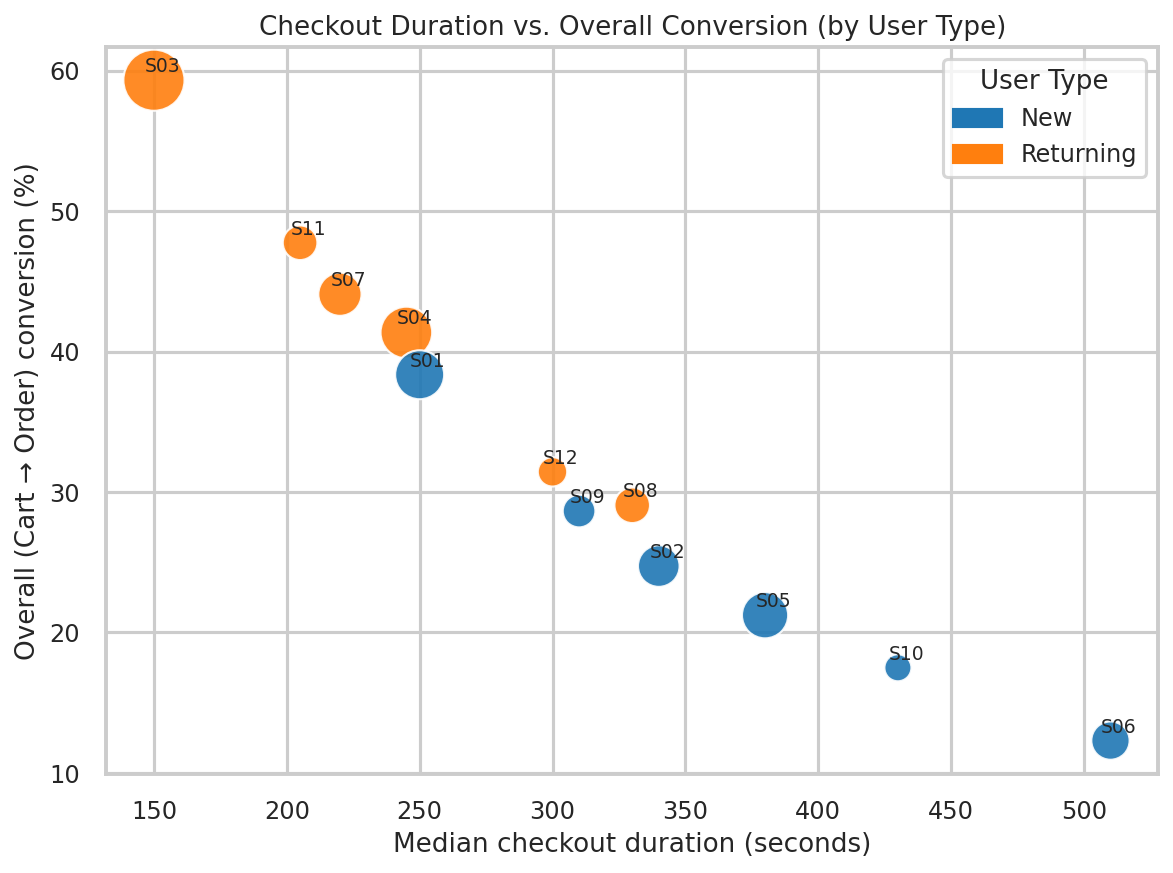

In [31]:
render_scatter(
    df["median_checkout_seconds"], df["overall conversion"], group_colors(df, "user_type", USER_TYPE_COLORS),
    sizes, df["segment_id"],
    title="Checkout Duration vs. Overall Conversion (by User Type)",
    xlabel="Median checkout duration (seconds)", ylabel="Overall (Cart → Order) conversion (%)",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="upper right",
    savepath=f"{FIGDIR}/07_duration_vs_conversion_user_type.png",
)


## 12. Chart 8 — Average Cart Value (Context Check)

**Why this chart:** cart value is a plausible candidate explanatory variable (higher-value
carts might see more hesitation or payment scrutiny). Included to show a signal that turns
out **not** to matter — a useful negative result, not just a positive one.

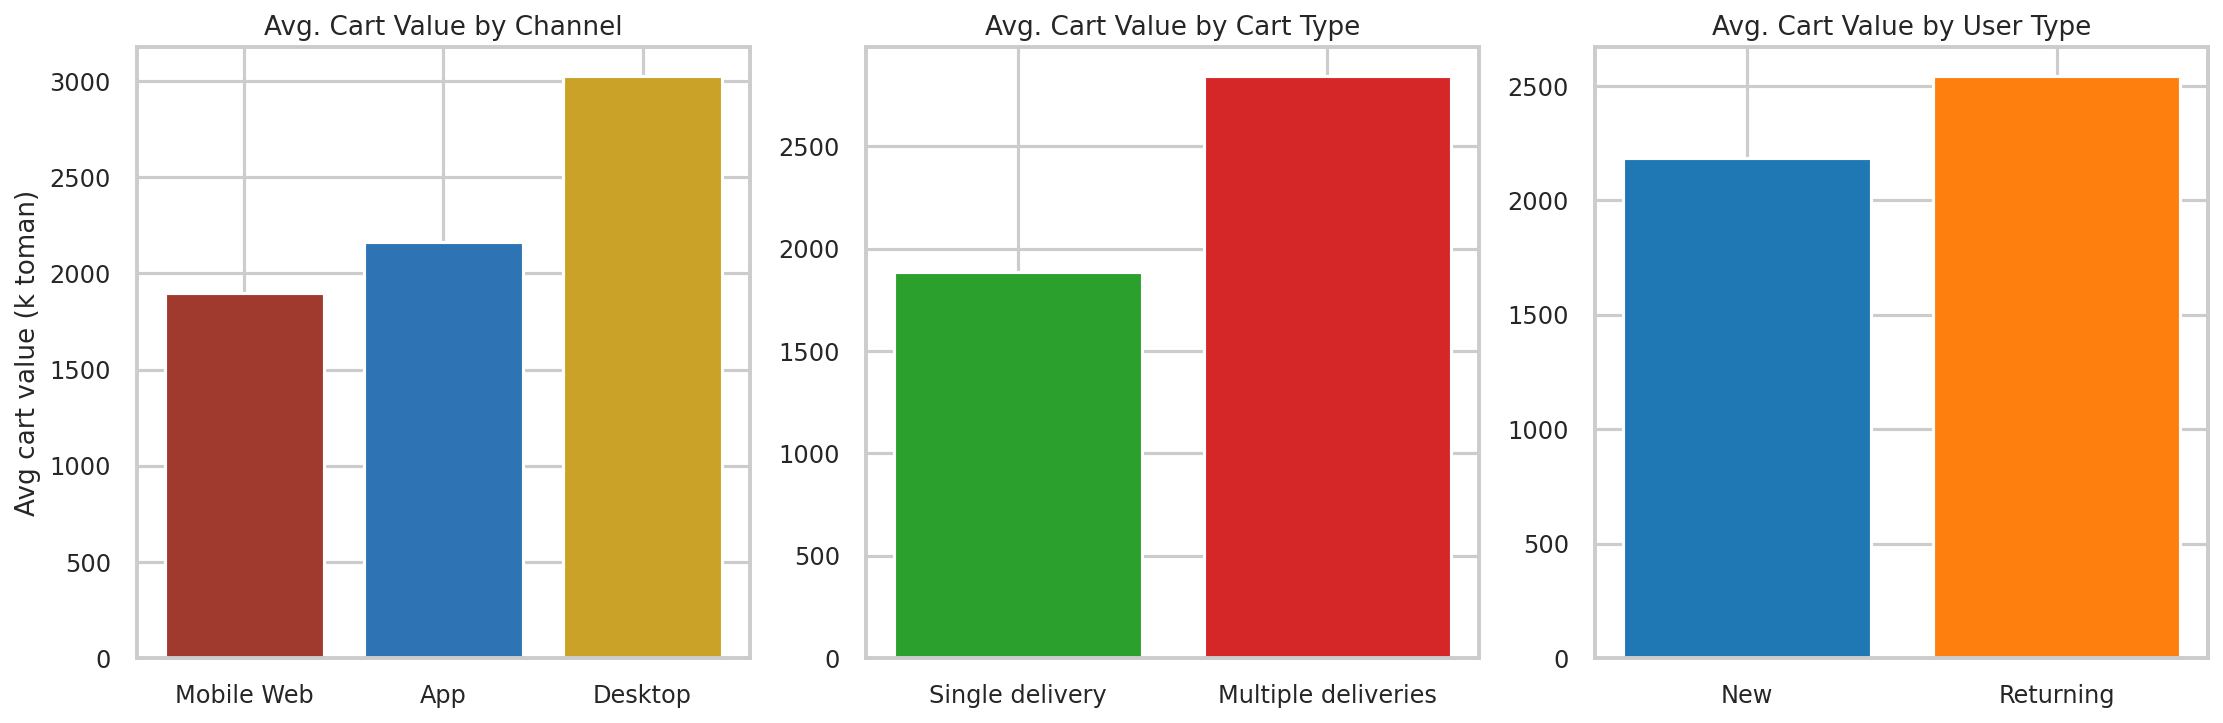

Correlation (avg_cart_value_k_toman vs overall conversion): r = -0.18  <- negligible


In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

g1 = df.groupby("channel")["avg_cart_value_k_toman"].mean().sort_values()
axes[0].bar(g1.index, g1.values, color=[CHANNEL_COLORS[c] for c in g1.index])
axes[0].set_title("Avg. Cart Value by Channel")
axes[0].set_ylabel("Avg cart value (k toman)")

g2 = df.groupby("cart_type")["avg_cart_value_k_toman"].mean().sort_values()
axes[1].bar(g2.index, g2.values, color=[CART_TYPE_COLORS[c] for c in g2.index])
axes[1].set_title("Avg. Cart Value by Cart Type")

g3 = df.groupby("user_type")["avg_cart_value_k_toman"].mean().sort_values()
axes[2].bar(g3.index, g3.values, color=[USER_TYPE_COLORS[c] for c in g3.index])
axes[2].set_title("Avg. Cart Value by User Type")

plt.tight_layout()
plt.savefig(f"{FIGDIR}/08_cart_value_context.png")
plt.show()

r = df["avg_cart_value_k_toman"].corr(df["overall conversion"])
print(f"Correlation (avg_cart_value_k_toman vs overall conversion): r = {r:.2f}  <- negligible")


## 13. Chart 9 — Correlation Heatmap (All Metrics)

**Why this chart:** summarizes every pairwise relationship at once and checks for
confounding — whether signals are independent or several are driven by one underlying factor.
**How to read it:** dark red = strong positive, dark blue = strong negative, near-white = none.

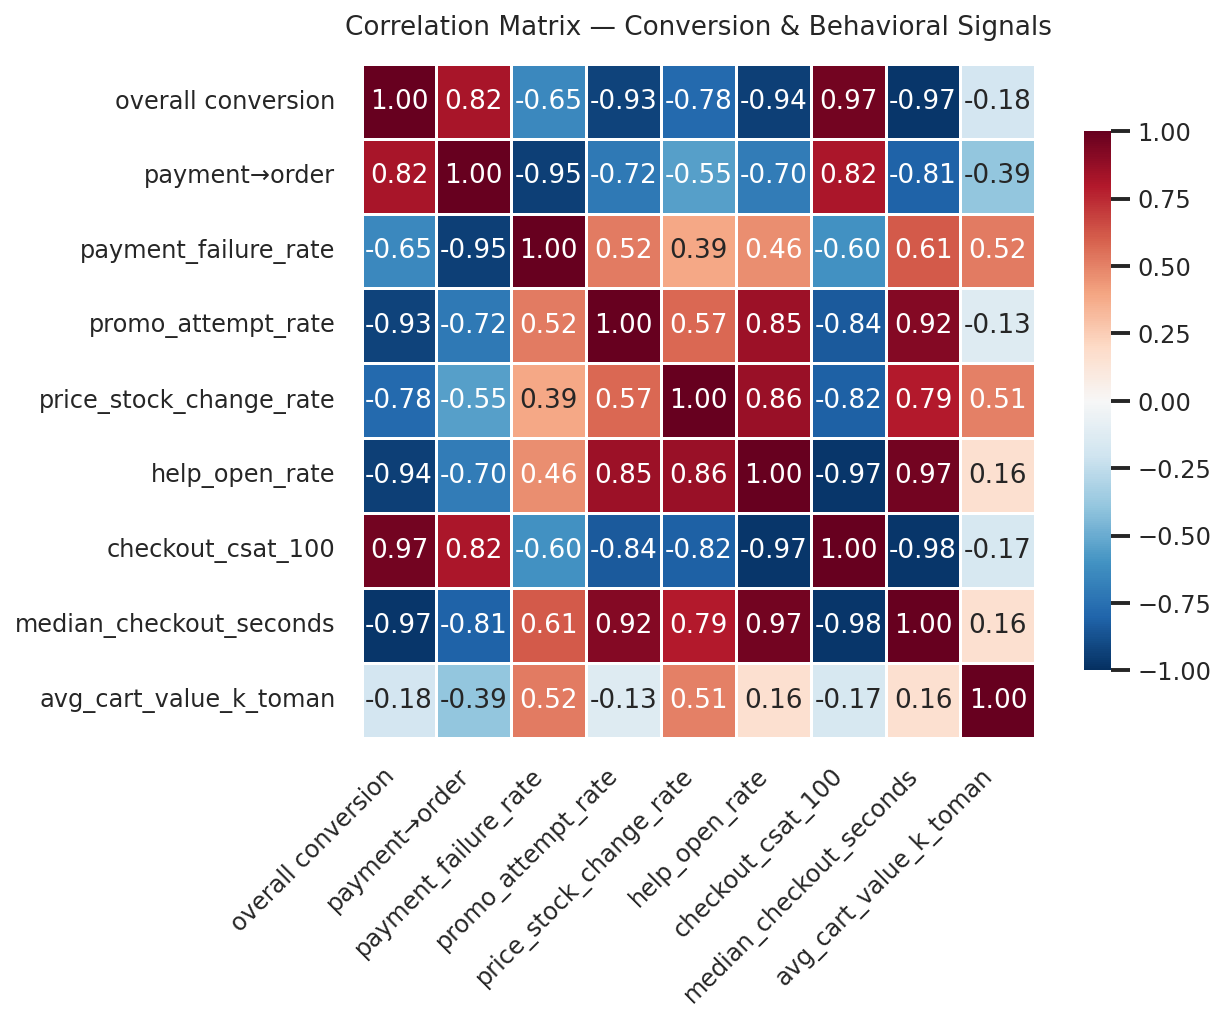

Correlation with overall conversion, sorted:
median_checkout_seconds   -0.970825
help_open_rate            -0.939757
promo_attempt_rate        -0.925299
price_stock_change_rate   -0.780600
payment_failure_rate      -0.647699
avg_cart_value_k_toman    -0.179898
payment→order              0.824018
checkout_csat_100          0.968445
overall conversion         1.000000
Name: overall conversion, dtype: float64


In [33]:
corr = df[METRIC_COLS].corr()
render_heatmap(corr, "Correlation Matrix — Conversion & Behavioral Signals",
                f"{FIGDIR}/09_correlation_heatmap.png")

print("Correlation with overall conversion, sorted:")
print(corr["overall conversion"].sort_values())


Two follow-on views of the same correlation data: the matrix re-sorted by strength of
relationship with overall conversion (easier to scan than the alphabetical version above),
and a rectangular matrix isolating just the behavioral signals against each funnel stage.

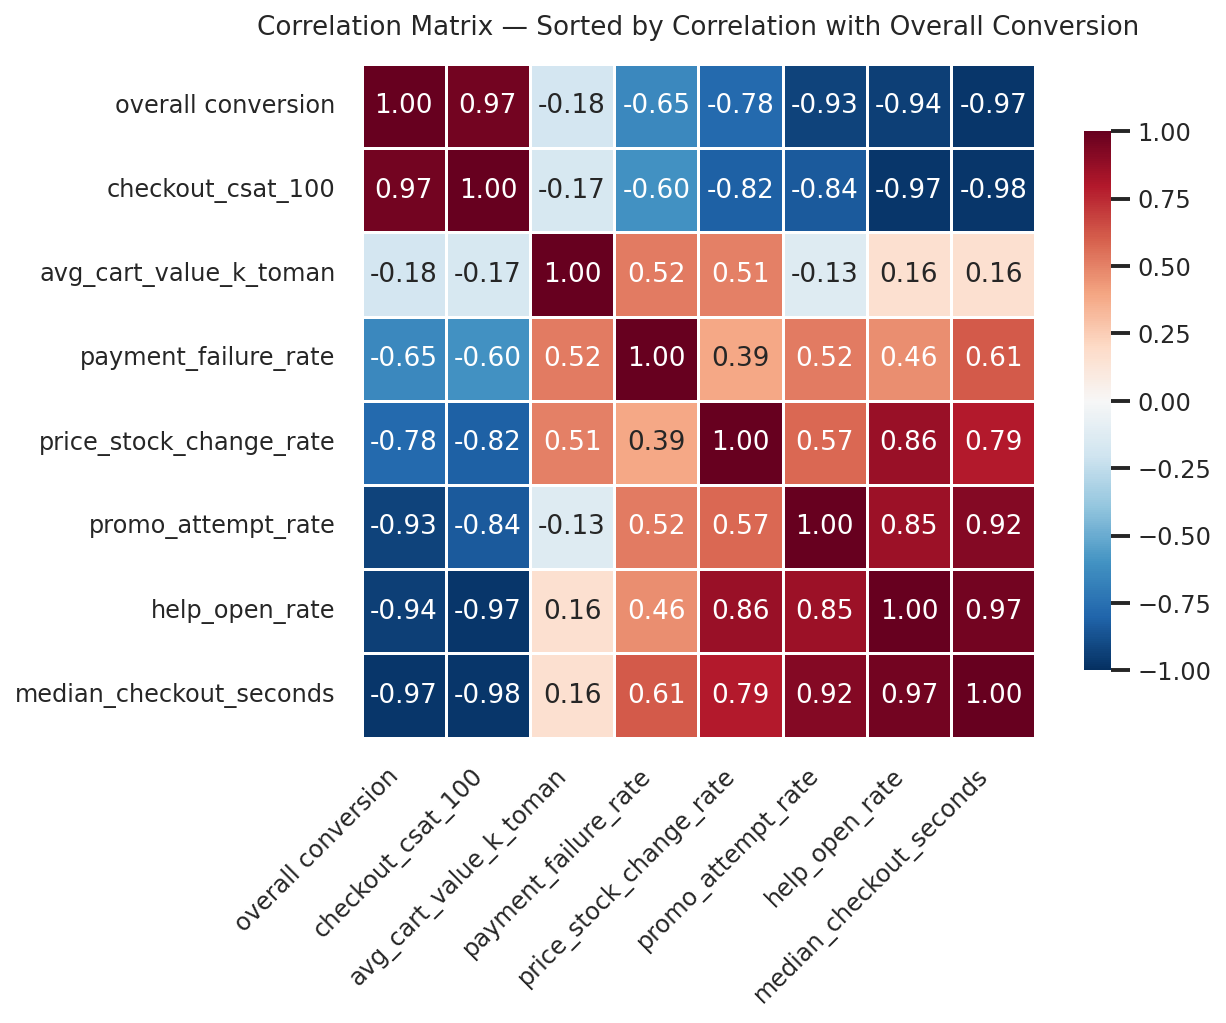

Correlation with overall conversion, sorted (High to Low):
overall conversion         1.000000
checkout_csat_100          0.968445
avg_cart_value_k_toman    -0.179898
payment_failure_rate      -0.647699
price_stock_change_rate   -0.780600
promo_attempt_rate        -0.925299
help_open_rate            -0.939757
median_checkout_seconds   -0.970825
Name: overall conversion, dtype: float64


In [34]:
# Re-sort the correlation matrix so the metrics most related to overall conversion
# (positively or negatively) are grouped together, rather than in alphabetical order.
cols_to_use = [col for col in METRIC_COLS if col != "payment→order"]
corr_no_payment = df[cols_to_use].corr()
sorted_cols = corr_no_payment["overall conversion"].sort_values(ascending=False).index
corr_sorted = corr_no_payment.loc[sorted_cols, sorted_cols]

render_heatmap(corr_sorted, "Correlation Matrix — Sorted by Correlation with Overall Conversion",
                f"{FIGDIR}/09_correlation_heatmap_sorted.png")

print("Correlation with overall conversion, sorted (High to Low):")
print(corr_sorted["overall conversion"])


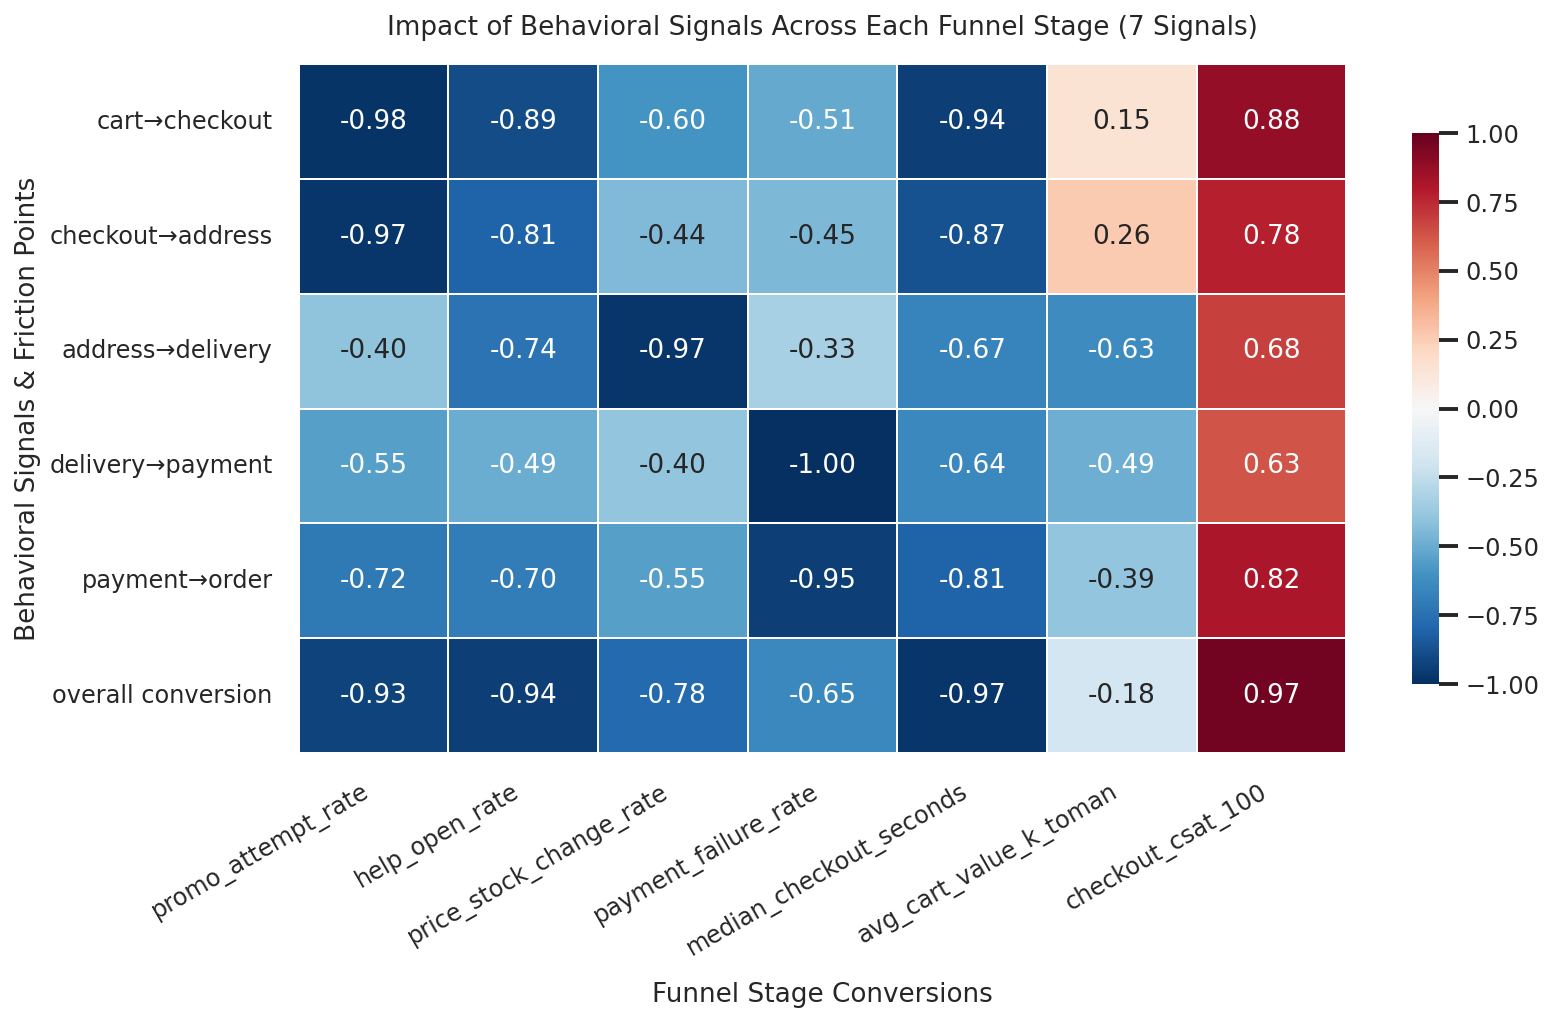

In [35]:
# Cross-correlation: every behavioral signal (rows) against every funnel-stage
# conversion (columns), so a specific signal-to-stage relationship is easy to spot.
funnel_steps = ["cart→checkout", "checkout→address", "address→delivery",
                 "delivery→payment", "payment→order", "overall conversion"]
behavioral_signals = ["promo_attempt_rate", "help_open_rate", "price_stock_change_rate",
                       "payment_failure_rate", "median_checkout_seconds",
                       "avg_cart_value_k_toman", "checkout_csat_100"]

cross_corr = df[behavioral_signals].apply(lambda x: df[funnel_steps].corrwith(x))

render_heatmap(
    cross_corr, "Impact of Behavioral Signals Across Each Funnel Stage (7 Signals)",
    f"{FIGDIR}/10_cross_funnel_correlation_matrix.png",
    figsize=(11, 7), rotation=30, linewidths=0.8, square=False,
    xlabel="Funnel Stage Conversions", ylabel="Behavioral Signals & Friction Points",
)


## 14. Chart 10 — Opportunity View (Prioritization Bubble Chart)

**Why this chart:** combines conversion, payment risk, and segment volume into a single view.
**How to read it:** top-left = most severe (low conversion, high payment risk); bubble size
= session volume, so severity and reach can be judged together.
**Note:** this chart deliberately stops short of a single weighted priority score — combining
severity and volume into one ranked list is a judgment call for the next phase, not this EDA.

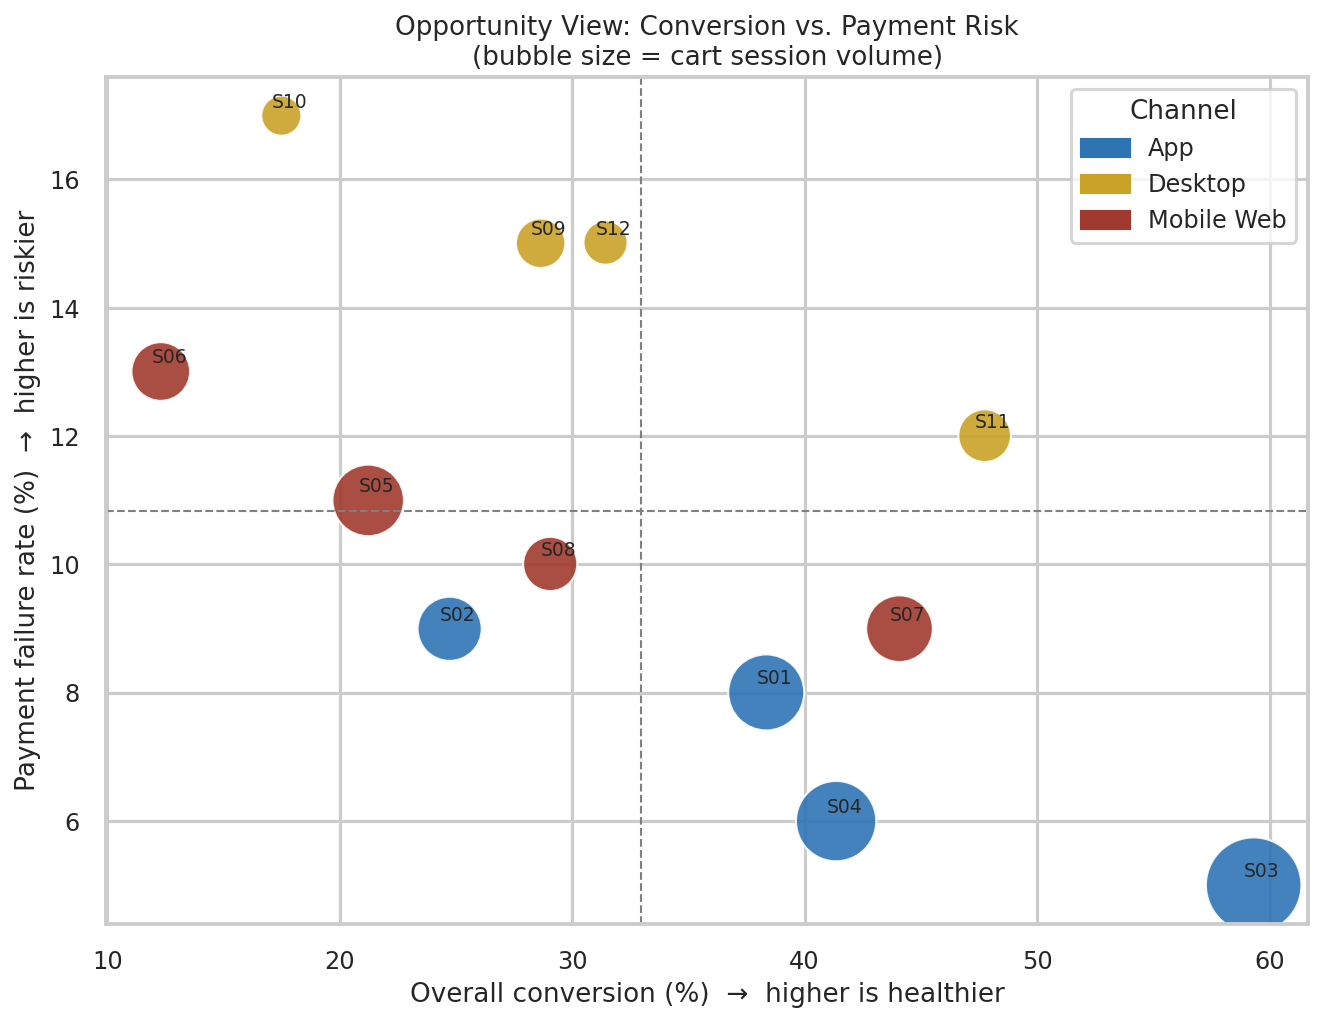

In [36]:
x, y = df["overall conversion"], df["payment_failure_rate"]
sizes = df["cart_sessions"] / df["cart_sessions"].max() * 2000 + 100
x_mean, y_mean = x.mean(), y.mean()

render_scatter(
    x, y, seg_colors(df), sizes, df["segment_id"],
    title="Opportunity View: Conversion vs. Payment Risk\n(bubble size = cart session volume)",
    xlabel="Overall conversion (%)  →  higher is healthier",
    ylabel="Payment failure rate (%)  →  higher is riskier",
    legend_handles=channel_handles, legend_title="Channel", legend_loc="upper right",
    savepath=f"{FIGDIR}/10_opportunity_bubble.png",
    vline=x_mean, hline=y_mean, figsize=(9, 7),
)


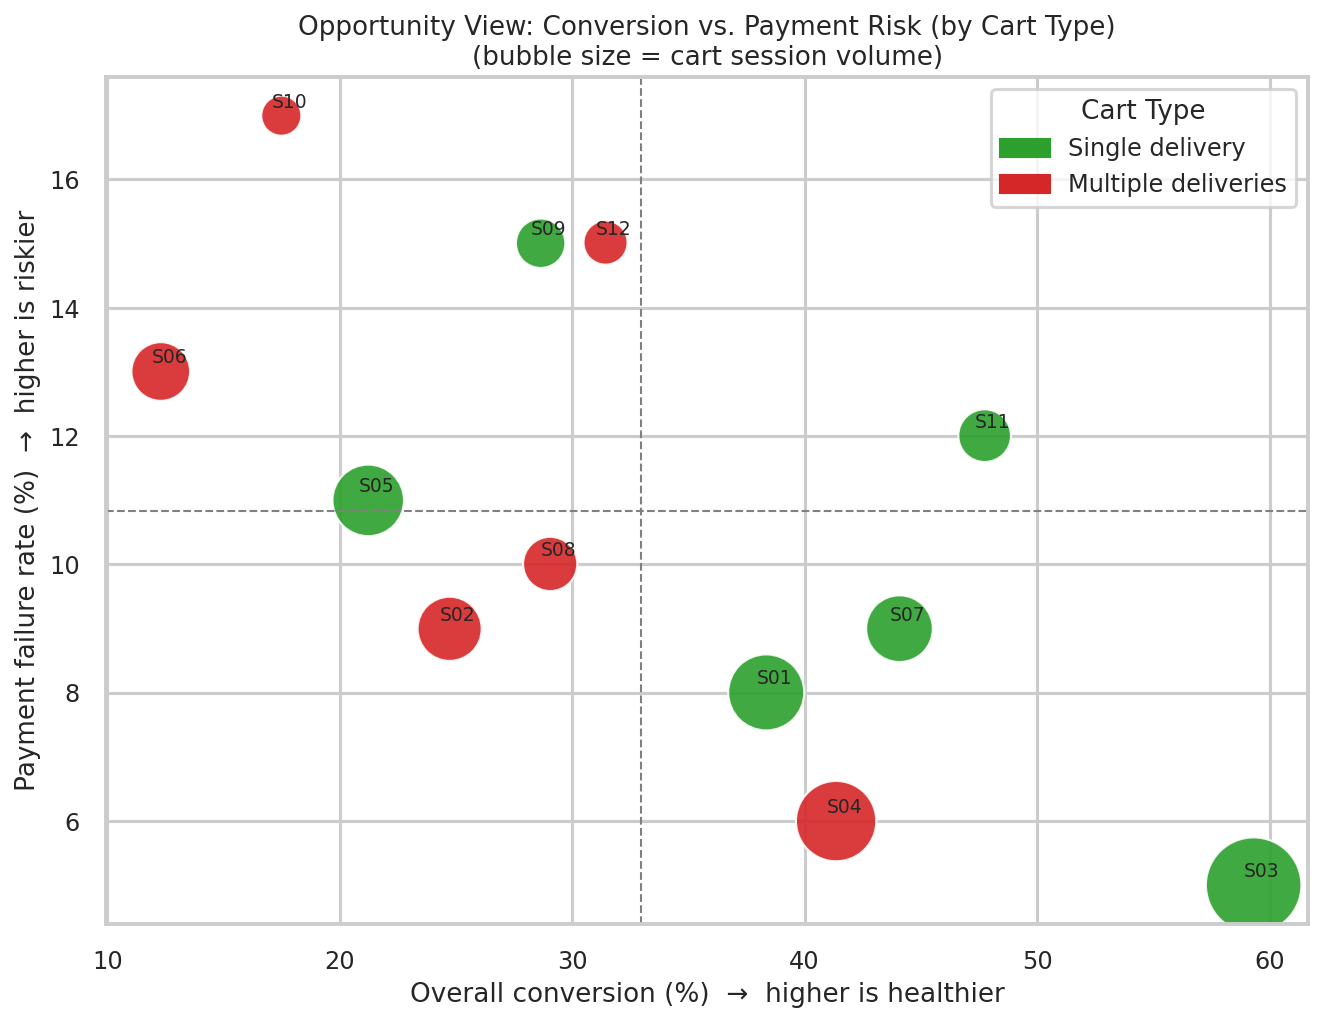

In [37]:
render_scatter(
    x, y, group_colors(df, "cart_type", CART_TYPE_COLORS), sizes, df["segment_id"],
    title="Opportunity View: Conversion vs. Payment Risk (by Cart Type)\n(bubble size = cart session volume)",
    xlabel="Overall conversion (%)  →  higher is healthier",
    ylabel="Payment failure rate (%)  →  higher is riskier",
    legend_handles=cart_type_handles, legend_title="Cart Type", legend_loc="upper right",
    savepath=f"{FIGDIR}/10_opportunity_bubble_cart_type.png",
    vline=x_mean, hline=y_mean, figsize=(9, 7),
)


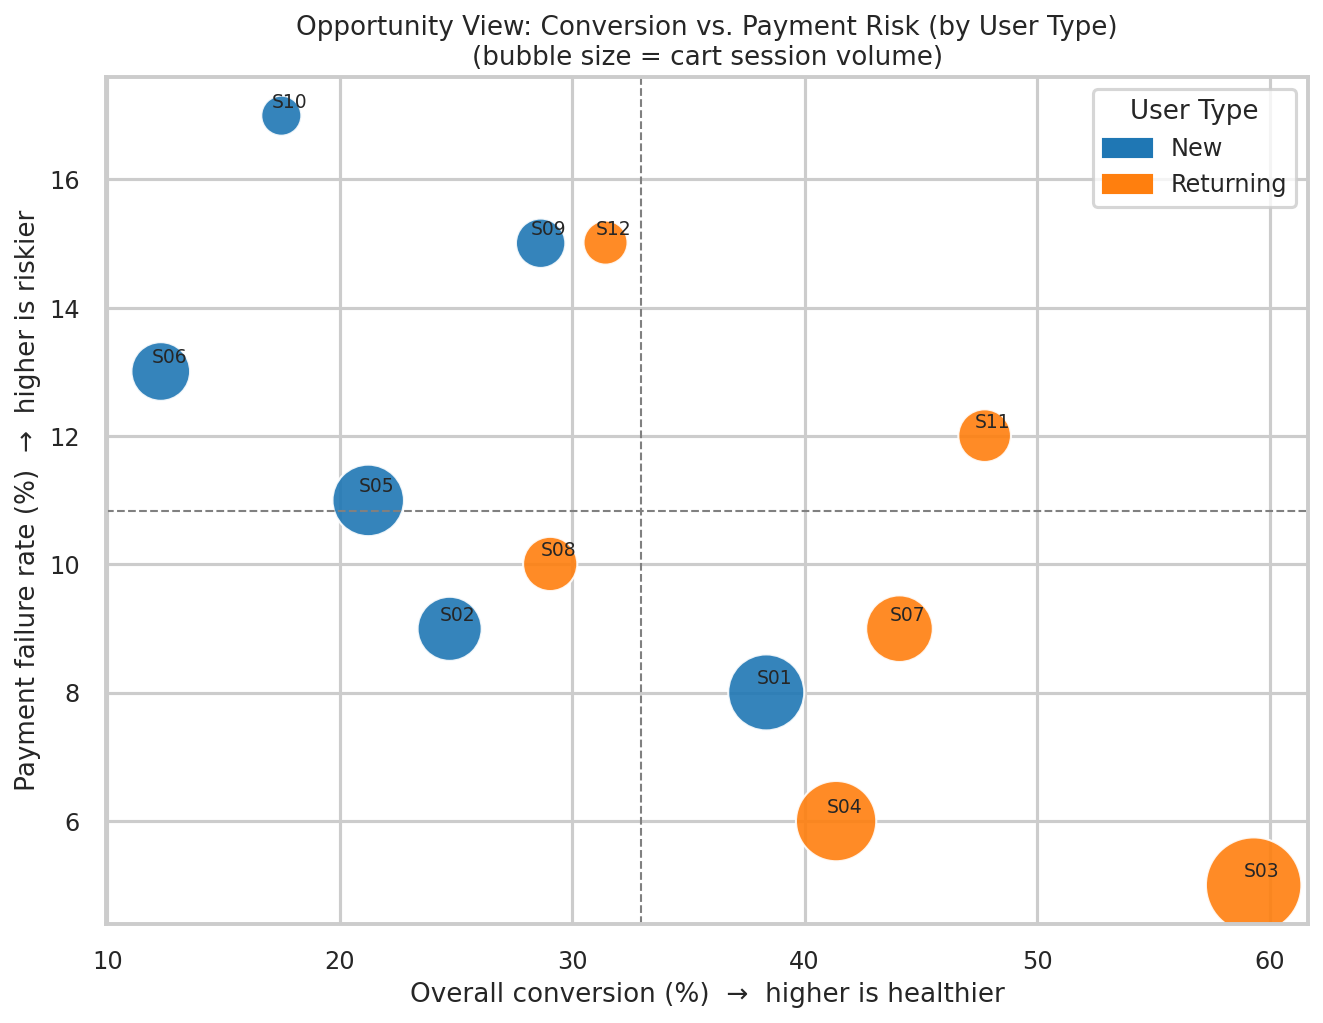

In [38]:
render_scatter(
    x, y, group_colors(df, "user_type", USER_TYPE_COLORS), sizes, df["segment_id"],
    title="Opportunity View: Conversion vs. Payment Risk (by User Type)\n(bubble size = cart session volume)",
    xlabel="Overall conversion (%)  →  higher is healthier",
    ylabel="Payment failure rate (%)  →  higher is riskier",
    legend_handles=user_type_handles, legend_title="User Type", legend_loc="upper right",
    savepath=f"{FIGDIR}/10_opportunity_bubble_user_type.png",
    vline=x_mean, hline=y_mean, figsize=(9, 7),
)


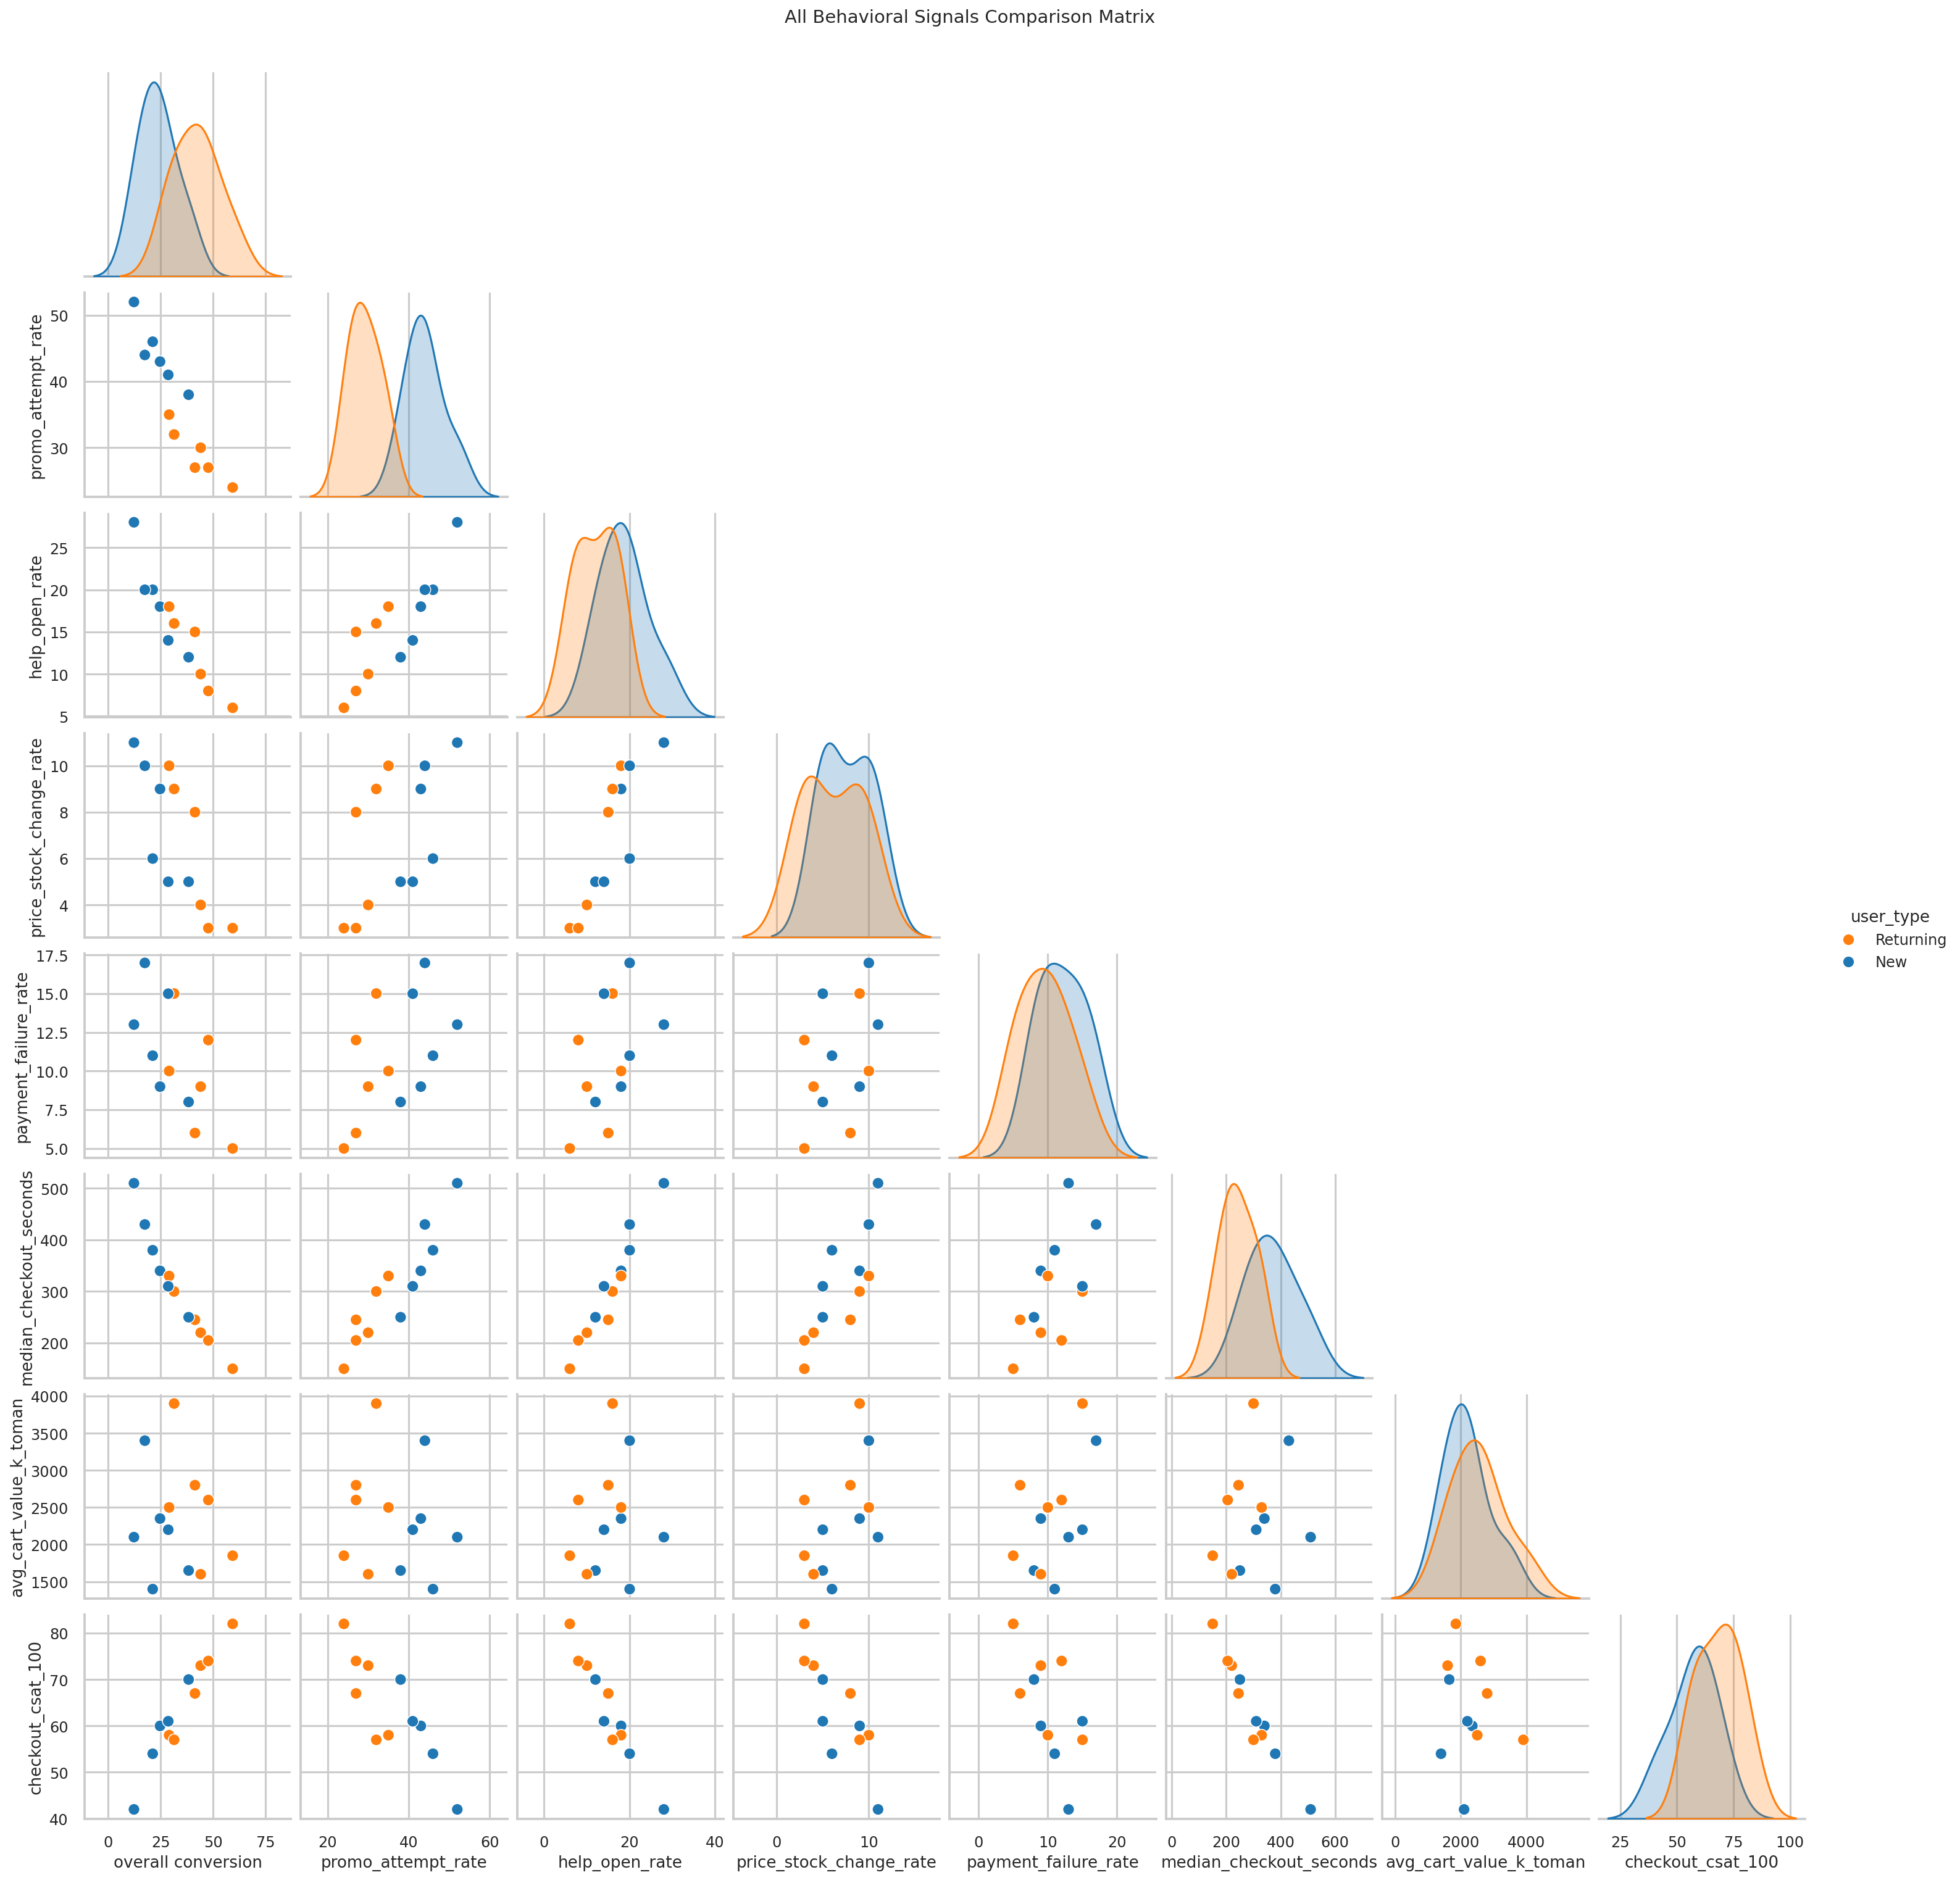

In [39]:
# All seven behavioral signals plus overall conversion, pairwise, split by user type.
signals_to_plot = [
    "overall conversion", "promo_attempt_rate", "help_open_rate", "price_stock_change_rate",
    "payment_failure_rate", "median_checkout_seconds", "avg_cart_value_k_toman", "checkout_csat_100",
]

g = sns.pairplot(
    df[signals_to_plot + ["user_type"]],
    hue="user_type", palette=USER_TYPE_COLORS, corner=True, diag_kind="kde",
)
g.fig.suptitle("All Behavioral Signals Comparison Matrix", y=1.02, fontsize=14)
plt.savefig(f"{FIGDIR}/11_all_signals_pairplot.png", bbox_inches="tight")
plt.show()


## 15. Key Findings & Hypotheses (Printed Summary)

Observations are data-verified; hypotheses are candidates for further investigation, not
conclusions. This mirrors the structure of the companion Word report.

In [40]:
print("=" * 70)
print("KEY FINDINGS (data-verified observations)")
print("=" * 70)
findings = [
    "Cart→Checkout is the single largest drop in the funnel on a weighted basis "
    "(~66% average conversion, ~34% of sessions lost before checkout even opens).",
    "Every behavioral signal tested correlates strongly (|r| > 0.8) with conversion "
    "at its matched funnel stage.",
    "Returning users convert at roughly double the rate of New users "
    f"({df.groupby('user_type')['overall conversion'].mean()['Returning']:.1f}% vs "
    f"{df.groupby('user_type')['overall conversion'].mean()['New']:.1f}%).",
    "Desktop holds 3 of the 4 highest payment-failure rates despite not being the "
    "lowest-converting channel overall.",
    "Average cart value shows almost no relationship with conversion (r ≈ -0.18).",
]
for f in findings:
    print(f"- {f}")

print()
print("=" * 70)
print("HYPOTHESES (need further validation — see Word report §8 for detail)")
print("=" * 70)
hypotheses = [
    "H1: Some payment failures reflect a technical/gateway issue concentrated on Desktop.",
    "H2: The visible promo-code field prompts users (especially New users) to leave and not return.",
    "H3: Mid-flow price/stock changes erode trust specifically at the delivery-selection step.",
    "H4: Multiple-delivery carts add comprehension cost, not just logistics cost.",
    "H5: New users face compounding, not isolated, frictions across several signals at once.",
]
for h in hypotheses:
    print(f"- {h}")


KEY FINDINGS (data-verified observations)
- Cart→Checkout is the single largest drop in the funnel on a weighted basis (~66% average conversion, ~34% of sessions lost before checkout even opens).
- Every behavioral signal tested correlates strongly (|r| > 0.8) with conversion at its matched funnel stage.
- Returning users convert at roughly double the rate of New users (42.2% vs 23.8%).
- Desktop holds 3 of the 4 highest payment-failure rates despite not being the lowest-converting channel overall.
- Average cart value shows almost no relationship with conversion (r ≈ -0.18).

HYPOTHESES (need further validation — see Word report §8 for detail)
- H1: Some payment failures reflect a technical/gateway issue concentrated on Desktop.
- H2: The visible promo-code field prompts users (especially New users) to leave and not return.
- H3: Mid-flow price/stock changes erode trust specifically at the delivery-selection step.
- H4: Multiple-delivery carts add comprehension cost, not just logistic

## 16. Retention Curves & Step-Gap Charts by Segment Dimension

Three paired charts, one per segment dimension (user type, cart type, channel): a retention
curve showing what share of the original cart sessions remain at each funnel stage per group,
and a step-gap bar chart showing exactly where the two reference groups diverge most.

All three reuse the already-cleaned `df` from Section 2 — no re-reading the source file.

In [41]:
stages = ["cart_sessions", "checkout_started", "address_completed",
          "delivery_selected", "payment_started", "orders_completed"]
stage_labels = ["Cart", "Checkout", "Address", "Delivery", "Payment", "Order"]


def retention_by_group(frame, group_col, groups):
    """% of each group's own cart_sessions still present at each funnel stage."""
    grouped = frame.groupby(group_col)[stages].sum()
    retention = pd.DataFrame(index=groups)
    for stage, label in zip(stages, stage_labels):
        retention[label] = grouped.loc[groups, stage] / grouped.loc[groups, "cart_sessions"] * 100
    return retention


def plot_retention_curve(retention, groups, colors, markers, title, savepath, label_offsets=None):
    """Line chart: % of cart sessions retained at each stage, one line per group."""
    fig, ax = plt.subplots(figsize=(8, 6))
    for g in groups:
        ax.plot(stage_labels, retention.loc[g], marker=markers[g], linewidth=2.5,
                markersize=8, color=colors[g], label=g)
    for x_idx, label in enumerate(stage_labels):
        for g in groups:
            val = retention.loc[g, label]
            offset = (label_offsets or {}).get(g, 8)
            ax.annotate(f"{val:.1f}%", (x_idx, val), textcoords="offset points",
                        xytext=(0, offset), ha="center", fontweight="bold",
                        color=colors[g], fontsize=9)
    ax.set_title(title, fontweight="bold", pad=15)
    ax.set_ylabel("% Remaining from Initial Cart Stage")
    ax.set_ylim(15, 110)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig(savepath)
    plt.show()


def plot_step_gap(gap, title, savepath, color="#9b59b6"):
    """Bar chart: retention gap (percentage points) between two reference groups, per stage."""
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(stage_labels, gap, color=color, width=0.5)
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:+.1f}%p", (bar.get_x() + bar.get_width() / 2, height),
                    ha="center", va="bottom", fontsize=10, fontweight="bold",
                    xytext=(0, 4), textcoords="offset points")
    ax.set_title(title, fontweight="bold", pad=15)
    ax.set_ylabel("Retention Gap (Percentage Points)")
    ax.set_ylim(0, 30)
    plt.tight_layout()
    plt.savefig(savepath)
    plt.show()


### 16.1 New vs. Returning Users

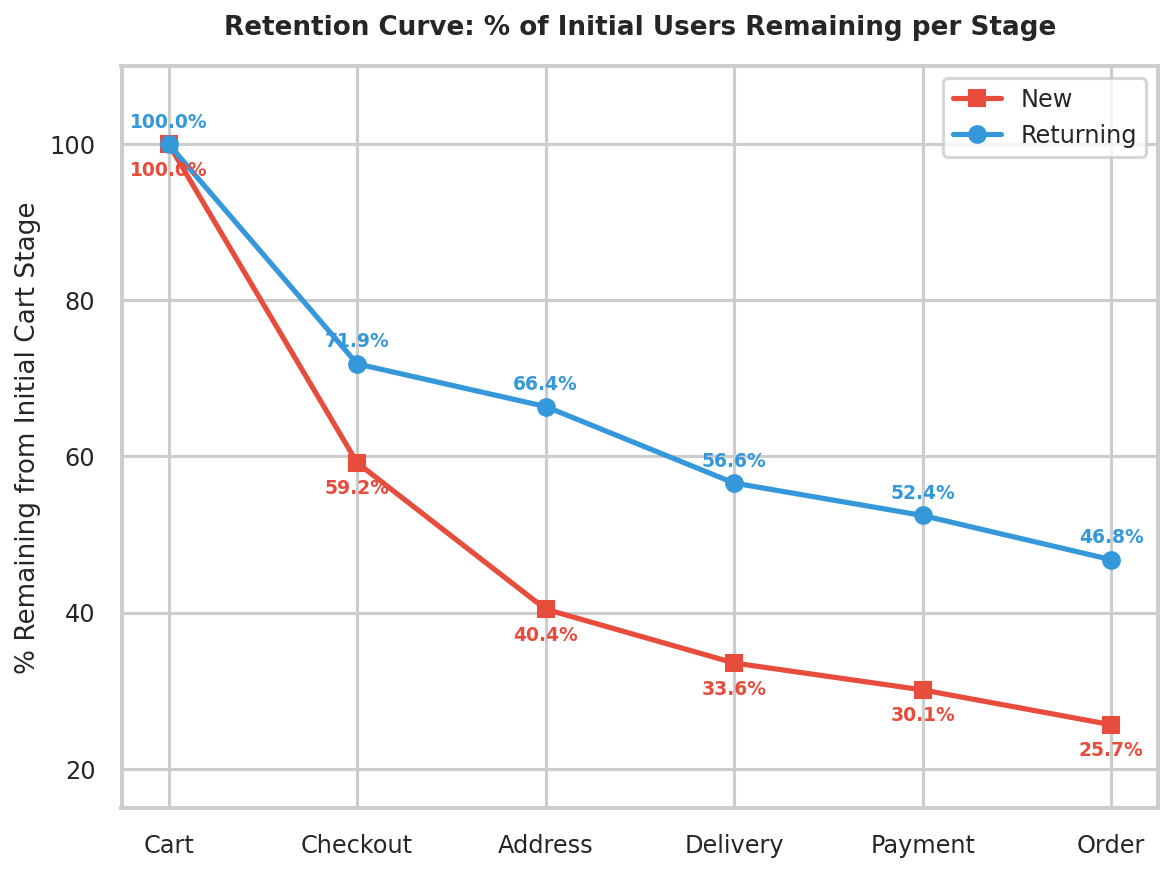

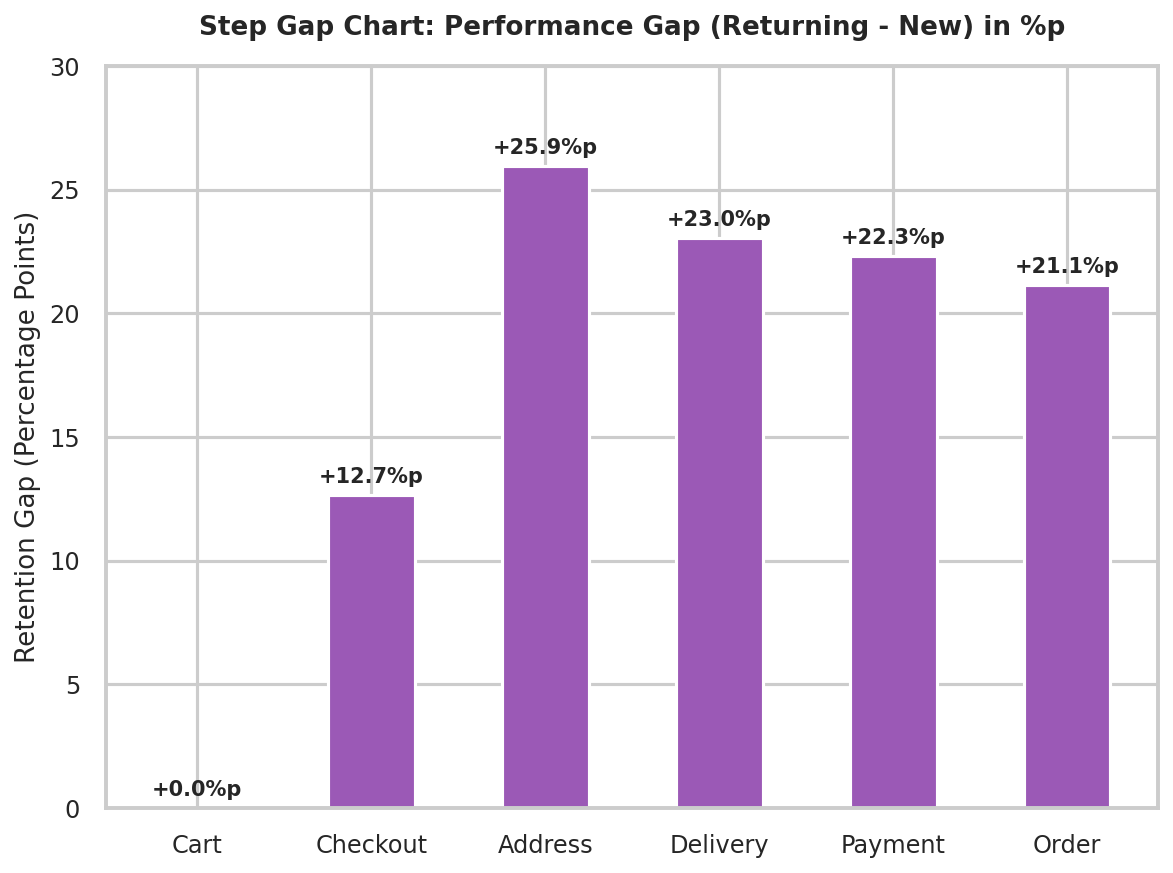

In [42]:
retention_user = retention_by_group(df, "user_type", ["New", "Returning"])
plot_retention_curve(
    retention_user, ["New", "Returning"],
    colors={"New": "#e74c3c", "Returning": "#3498db"},
    markers={"New": "s", "Returning": "o"},
    label_offsets={"New": -15, "Returning": 8},
    title="Retention Curve: % of Initial Users Remaining per Stage",
    savepath=f"{FIGDIR}/12_retention_user_type.png",
)

gap_user = retention_user.loc["Returning"] - retention_user.loc["New"]
plot_step_gap(gap_user, "Step Gap Chart: Performance Gap (Returning - New) in %p",
              f"{FIGDIR}/12_step_gap_user_type.png")


### 16.2 Single vs. Multiple Delivery Carts

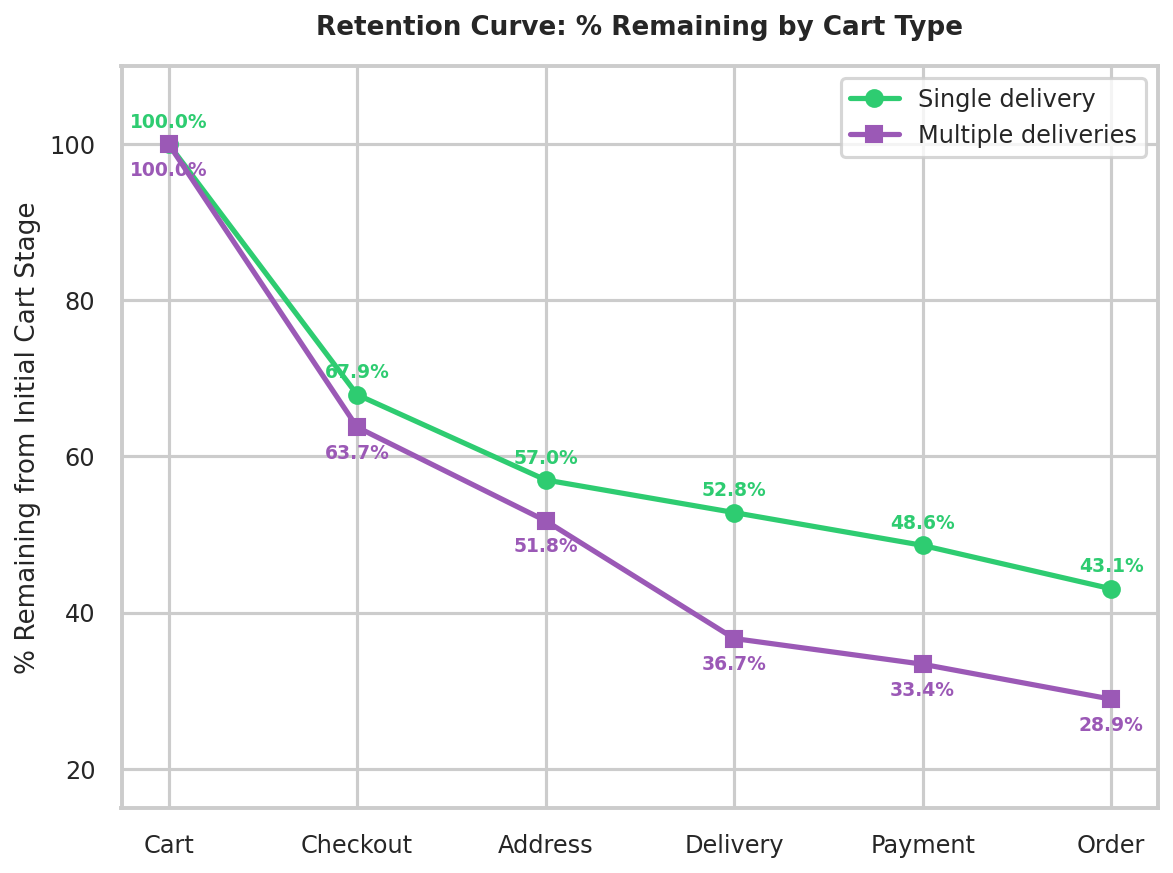

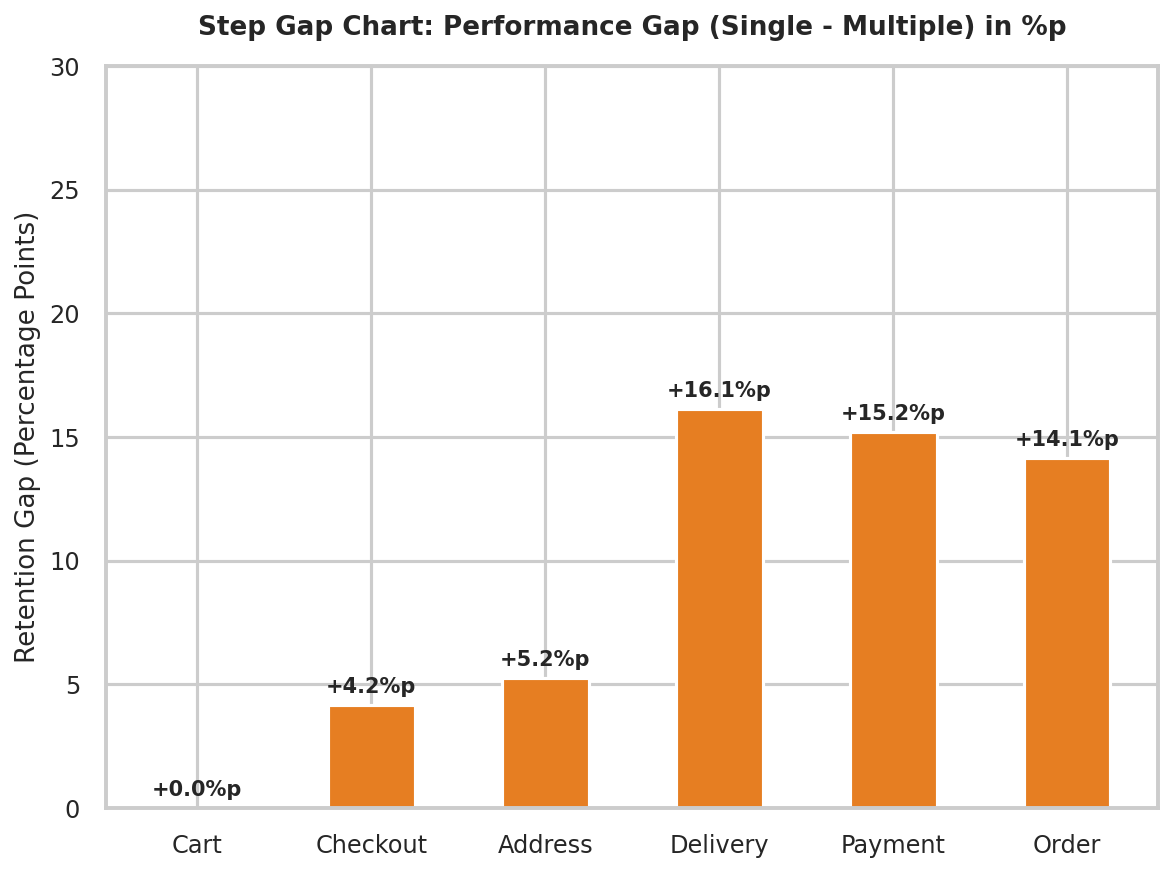

In [43]:
retention_cart = retention_by_group(df, "cart_type", ["Single delivery", "Multiple deliveries"])
plot_retention_curve(
    retention_cart, ["Single delivery", "Multiple deliveries"],
    colors={"Single delivery": "#2ecc71", "Multiple deliveries": "#9b59b6"},
    markers={"Single delivery": "o", "Multiple deliveries": "s"},
    label_offsets={"Single delivery": 8, "Multiple deliveries": -15},
    title="Retention Curve: % Remaining by Cart Type",
    savepath=f"{FIGDIR}/13_retention_cart_type.png",
)

gap_cart = retention_cart.loc["Single delivery"] - retention_cart.loc["Multiple deliveries"]
plot_step_gap(gap_cart, "Step Gap Chart: Performance Gap (Single - Multiple) in %p",
              f"{FIGDIR}/13_step_gap_cart_type.png", color="#e67e22")


### 16.3 Channel (App / Desktop / Mobile Web)

The gap chart for this dimension isolates App vs. Mobile Web specifically, since those two
sit at opposite ends of the retention curve.

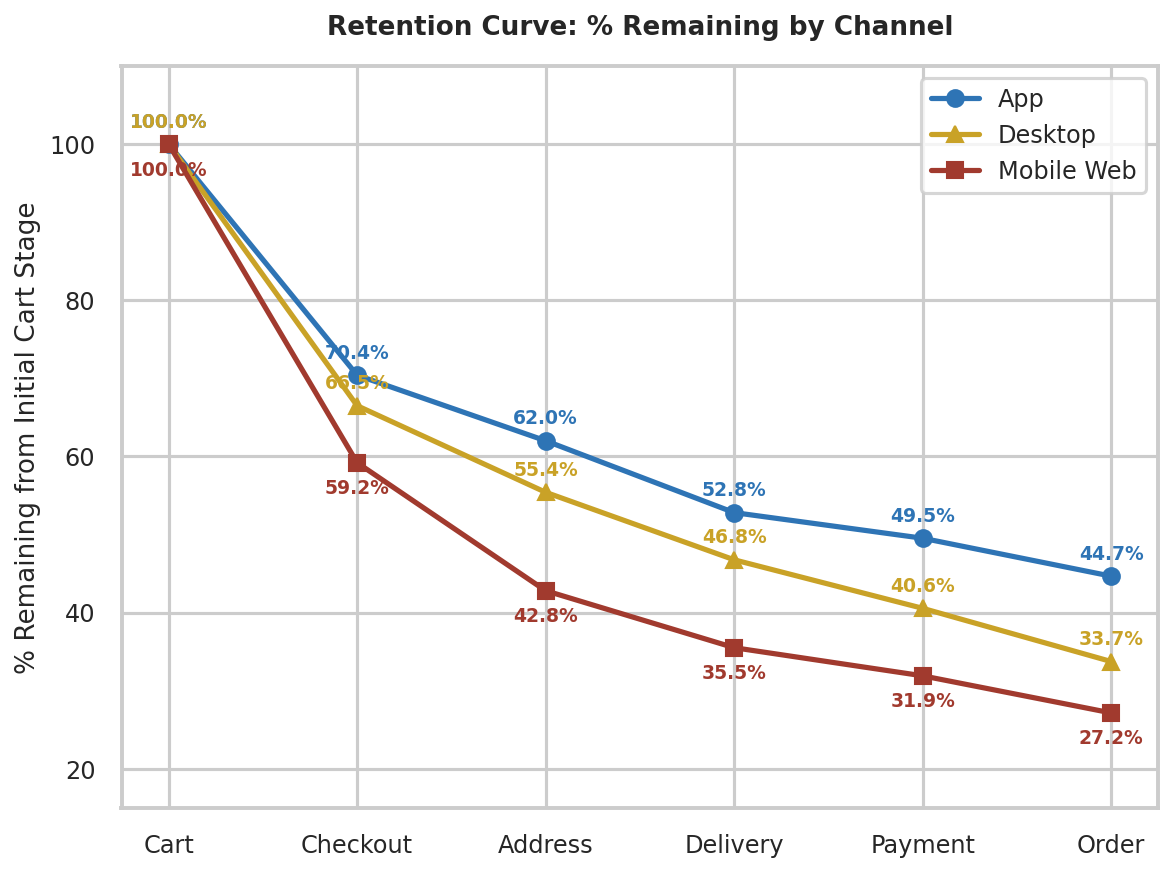

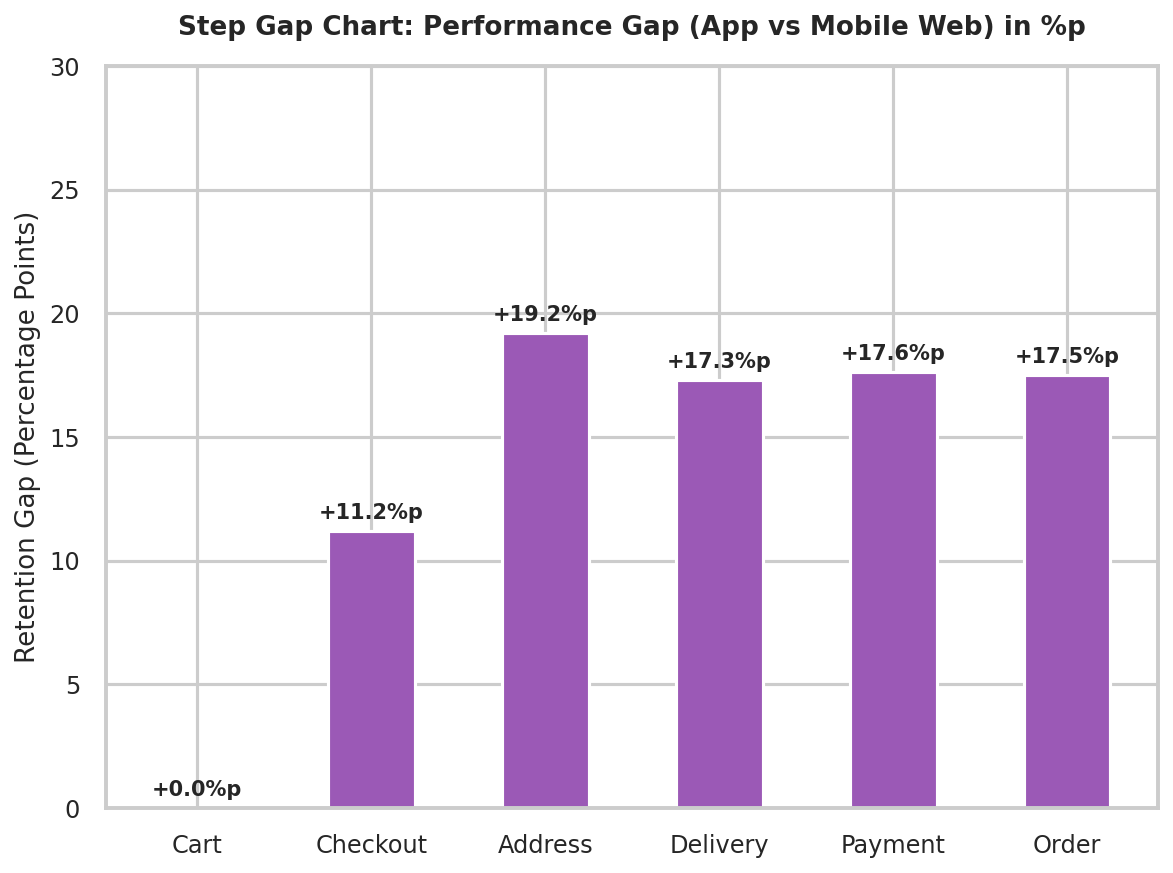

In [44]:
channels = ["App", "Desktop", "Mobile Web"]
retention_channel = retention_by_group(df, "channel", channels)

channel_markers = {"App": "o", "Desktop": "^", "Mobile Web": "s"}
channel_offsets = {"App": 8, "Desktop": 8, "Mobile Web": -15}

plot_retention_curve(
    retention_channel, channels, colors=CHANNEL_COLORS, markers=channel_markers,
    label_offsets=channel_offsets,
    title="Retention Curve: % Remaining by Channel",
    savepath=f"{FIGDIR}/14_retention_channel.png",
)

gap_channel = retention_channel.loc["App"] - retention_channel.loc["Mobile Web"]
plot_step_gap(gap_channel, "Step Gap Chart: Performance Gap (App vs Mobile Web) in %p",
              f"{FIGDIR}/14_step_gap_channel.png")


## 17. Segment Prioritization Matrix (Traffic vs. Conversion)

A four-quadrant view combining traffic volume (cart sessions) and overall conversion, to
separate segments worth prioritizing (high traffic, low conversion) from segments that are
already healthy (high traffic, high conversion) or lower-priority (low traffic).

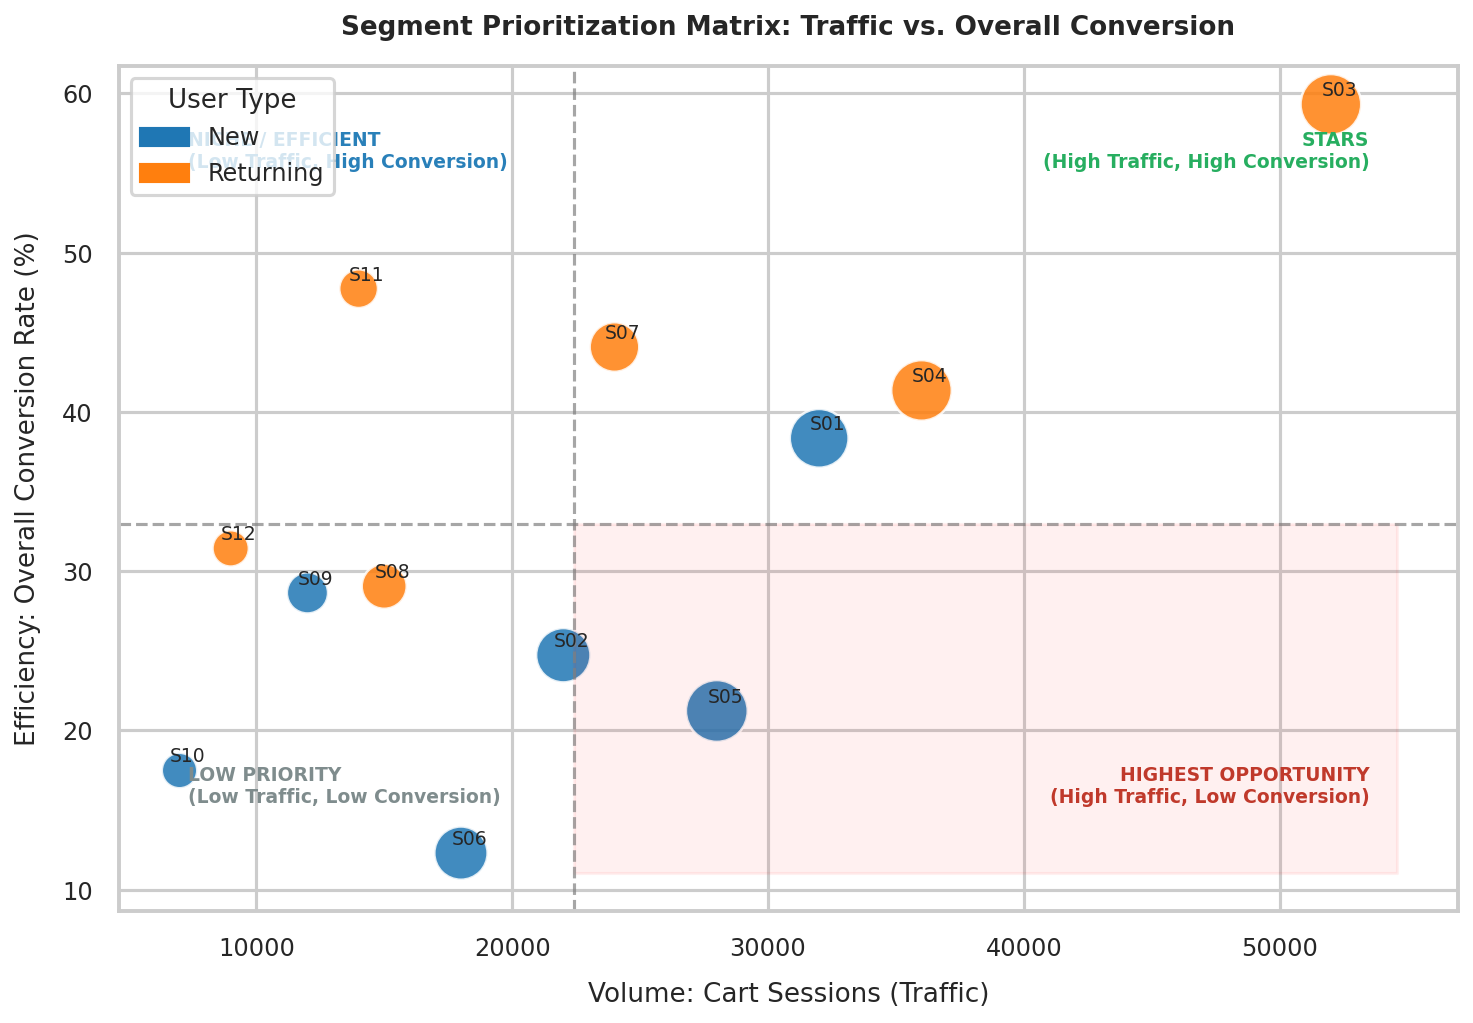

In [45]:
x_col, y_col = "cart_sessions", "overall conversion"
x_mean, y_mean = df[x_col].mean(), df[y_col].mean()

# Bubble size reflects sessions lost (cart_sessions - orders_completed) for this chart.
dropped_sessions = df["cart_sessions"] - df["orders_completed"]
sizes = dropped_sessions / dropped_sessions.max() * 800 + 80

colors = group_colors(df, "user_type", USER_TYPE_COLORS)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(df[x_col], df[y_col], c=colors, s=sizes, edgecolor="white", linewidth=1.2, alpha=0.85)
annotate_points(ax, df[x_col], df[y_col], df["segment_id"])

ax.axvline(x=x_mean, color="gray", linestyle="--", linewidth=1.5, alpha=0.7)
ax.axhline(y=y_mean, color="gray", linestyle="--", linewidth=1.5, alpha=0.7)

# Highlight the "high traffic, low conversion" quadrant as the primary opportunity zone.
x_max = df[x_col].max() * 1.05
y_min = df[y_col].min() * 0.9
ax.fill_between([x_mean, x_max], y_min, y_mean, color="#ff0000", alpha=0.06)

quadrant_labels = [
    (x_max * 0.98, y_mean * 0.5, "HIGHEST OPPORTUNITY\n(High Traffic, Low Conversion)",
     "#c0392b", "right"),
    (x_max * 0.98, df[y_col].max() * 0.95, "STARS\n(High Traffic, High Conversion)",
     "#27ae60", "right"),
    (df[x_col].min() * 1.05, df[y_col].max() * 0.95, "NICHE / EFFICIENT\n(Low Traffic, High Conversion)",
     "#2980b9", "left"),
    (df[x_col].min() * 1.05, y_mean * 0.5, "LOW PRIORITY\n(Low Traffic, Low Conversion)",
     "#7f8c8d", "left"),
]
for tx, ty, text, color, ha in quadrant_labels:
    ax.text(tx, ty, text, fontsize=9, color=color, fontweight="bold", ha=ha, va="center")

ax.set_xlabel("Volume: Cart Sessions (Traffic)", labelpad=10)
ax.set_ylabel("Efficiency: Overall Conversion Rate (%)", labelpad=10)
ax.set_title("Segment Prioritization Matrix: Traffic vs. Overall Conversion", fontweight="bold", pad=15)
ax.legend(handles=user_type_handles, title="User Type", loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/15_prioritization_matrix.png", dpi=300)
plt.show()


## 18. Total Financial Opportunity / Lost Revenue by Segment

Approximates the revenue represented by sessions that dropped out of each segment's funnel
(cart_sessions − orders_completed), using average cart value as a proxy for order value where
no dedicated AOV column exists in the source data.

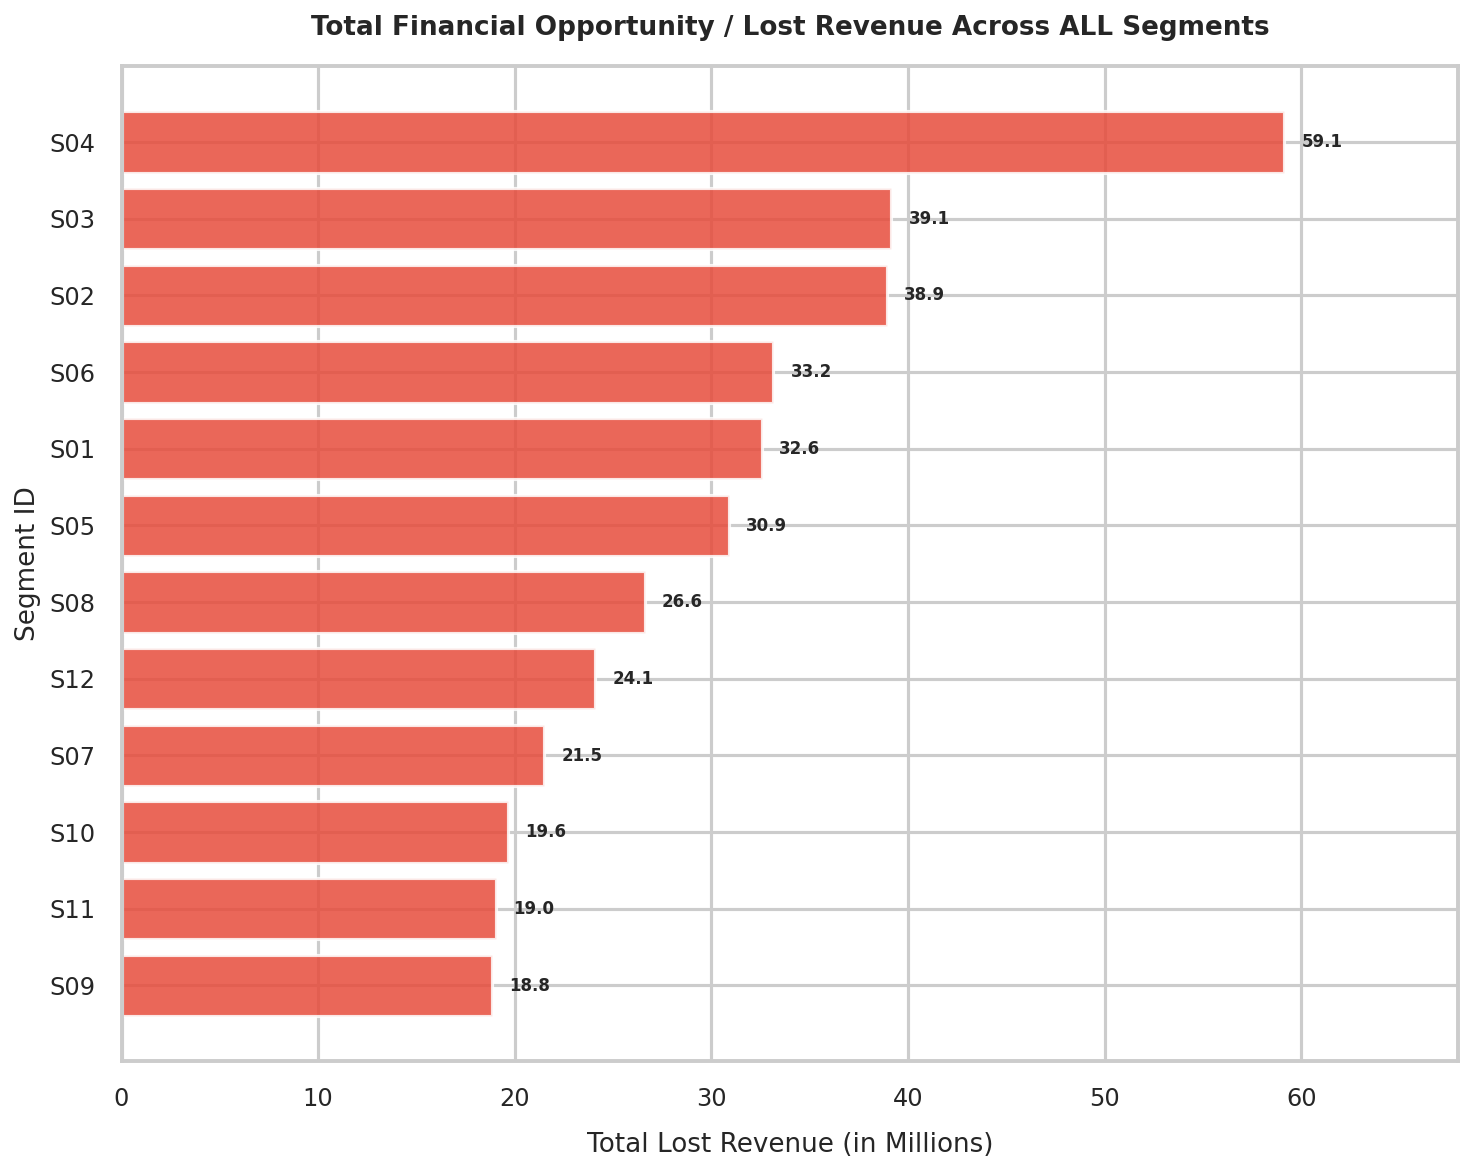

In [46]:
aov_column_candidates = ["aov", "AOV", "average_order_value", "avg_order_value", "mean_cart_value"]
aov_col = next((c for c in aov_column_candidates if c in df.columns), None)
df["aov_calculated"] = df[aov_col] if aov_col else df.get("avg_cart_value_k_toman", 100)

df["dropped_sessions"] = df["cart_sessions"] - df["orders_completed"]
df["total_lost_revenue"] = df["dropped_sessions"] * df["aov_calculated"]

df_sorted = df.sort_values(by="total_lost_revenue", ascending=True)

max_val = df_sorted["total_lost_revenue"].max()
scale = 1e6 if max_val >= 1e6 else (1e3 if max_val >= 1e3 else 1)
unit_label = "(in Millions)" if scale == 1e6 else ("(in Thousands)" if scale == 1e3 else "")

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(df_sorted["segment_id"].astype(str), df_sorted["total_lost_revenue"] / scale,
                color="#e74c3c", alpha=0.85, edgecolor="white")

for bar in bars:
    width = bar.get_width()
    ax.text(width + (max_val / scale * 0.015), bar.get_y() + bar.get_height() / 2,
            f"{width:,.1f}", ha="left", va="center", fontsize=8, fontweight="bold")

ax.set_xlabel(f"Total Lost Revenue {unit_label}", labelpad=10)
ax.set_ylabel("Segment ID")
ax.set_title("Total Financial Opportunity / Lost Revenue Across ALL Segments", fontweight="bold", pad=15)
ax.set_xlim(0, (max_val / scale) * 1.15)

plt.tight_layout()
plt.savefig(f"{FIGDIR}/16_all_segments_lost_revenue.png", dpi=300)
plt.show()
